# SignaVision : reconnaissance de panneaux de signalisation

**Projet Deep Learning, CY Tech ING3 2026-2027** · Nathan GUIHOT, Elyes DOS SANTOS · encadrante : Hanane Zerdoum

Classification de panneaux déjà recadrés sur le dataset GTSRB (43 classes), en suivant les six parties du sujet : données, modèle de référence, CNN, entraînement, évaluation, expériences. La démonstration du modèle final est à la fin.

Le notebook s'exécute de bout en bout, sur Colab comme en local. Les données sont téléchargées automatiquement et chaque modèle est sauvegardé dans `~/.cache/signavision` : aux exécutions suivantes, il est rechargé au lieu d'être réentraîné (`RETRAIN = True` pour tout refaire). Première exécution complète sur CPU : deux à trois heures, dont plus d'une pour le modèle final. Beaucoup moins sur un GPU Colab.

## 0. Mise en place

In [ ]:
# Imports, constantes globales et style des graphiques
import json
import os
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import kagglehub
import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from keras import layers
from matplotlib.colors import LogNorm
from PIL import Image, ImageOps
from sklearn.metrics import classification_report, confusion_matrix, f1_score

SEED = 42
IMG_SIZE = 32
WORK_DIR = Path.home() / ".cache" / "signavision"  # modèles et historiques sauvegardés
WORK_DIR.mkdir(parents=True, exist_ok=True)
RETRAIN = False  

keras.utils.set_random_seed(SEED)  
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
})
BLUE, ORANGE, GRAY, GOOD, BAD = "#2a78d6", "#eb6834", "#52514e", "#008300", "#e34948"

print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("GPU :", tf.config.list_physical_devices("GPU") or "aucun, entraînement sur CPU")

C:\Users\elyes\AppData\Roaming\Python\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


TensorFlow 2.21.0 | Keras 3.15.1
GPU : aucun, entraînement sur CPU


## Partie 1 : recherche, compréhension et préparation des données

### 1.1 Choix du dataset

Nous utilisons le **German Traffic Sign Recognition Benchmark (GTSRB)**, créé pour IJCNN 2011 par J. Stallkamp, M. Schlipsing, J. Salmen et C. Igel (Ruhr-Universität Bochum). C'est la référence pour la classification de panneaux : photos réelles prises depuis une voiture, un seul panneau par image, déjà recadré. Cela correspond exactement aux parties 1 à 6.

- Site officiel : https://benchmark.ini.rub.de/gtsrb_dataset.html
- Copie utilisée : https://www.kaggle.com/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign (mêmes images en PNG, avec les labels officiels du test)
- Licence : libre pour la recherche et l'enseignement, avec citation de Stallkamp et al. (2012), *Man vs. computer: Benchmarking machine learning algorithms for traffic sign recognition*, Neural Networks 32.

Le dataset ne donne que des numéros de classe : nous les avons associés aux panneaux grâce aux pictogrammes de `Meta/`, puis regroupés en six familles pour analyser les résultats.

In [2]:
# Noms des 43 classes et regroupement en familles
CLASS_NAMES = [
    "Limitation 20 km/h", "Limitation 30 km/h", "Limitation 50 km/h", "Limitation 60 km/h",
    "Limitation 70 km/h", "Limitation 80 km/h", "Fin de limitation 80 km/h", "Limitation 100 km/h",
    "Limitation 120 km/h", "Interdiction de dépasser", "Interdiction de dépasser (> 3,5 t)",
    "Priorité à la prochaine intersection", "Route prioritaire", "Cédez le passage", "Stop",
    "Circulation interdite", "Accès interdit (> 3,5 t)", "Sens interdit", "Autres dangers",
    "Virage à gauche", "Virage à droite", "Succession de virages", "Chaussée déformée",
    "Chaussée glissante", "Chaussée rétrécie par la droite", "Travaux", "Feux tricolores",
    "Passage piétons", "Enfants", "Cyclistes", "Neige ou verglas", "Animaux sauvages",
    "Fin de toutes les interdictions", "Tourner à droite", "Tourner à gauche", "Tout droit",
    "Tout droit ou à droite", "Tout droit ou à gauche", "Contournement par la droite",
    "Contournement par la gauche", "Carrefour giratoire", "Fin d'interdiction de dépasser",
    "Fin d'interdiction de dépasser (> 3,5 t)",
]
NUM_CLASSES = len(CLASS_NAMES)

# Regroupement en six familles, uniquement pour analyser les résultats
FAMILIES = {
    "Limitation de vitesse": [0, 1, 2, 3, 4, 5, 7, 8],
    "Fin d'interdiction": [6, 32, 41, 42],
    "Interdiction": [9, 10, 15, 16, 17],
    "Priorité": [11, 12, 13, 14],
    "Danger": list(range(18, 32)),
    "Obligation": list(range(33, 41)),
}
CLASS_FAMILY = {c: family for family, ids in FAMILIES.items() for c in ids}
# Chaque classe appartient à exactement une famille
assert sorted(CLASS_FAMILY) == list(range(NUM_CLASSES))


def short_name(c, n=17):
    name = CLASS_NAMES[c]
    return name if len(name) <= n else name[: n - 1] + "…"

In [3]:
# Téléchargement du dataset et lecture des CSV
DATA_DIR = Path(kagglehub.dataset_download("meowmeowmeowmeowmeow/gtsrb-german-traffic-sign"))
train_df = pd.read_csv(DATA_DIR / "Train.csv")
test_df = pd.read_csv(DATA_DIR / "Test.csv")
# Fichiers du train : classe_séquence_image. On garde la séquence pour découper la validation (1.6)
train_df["track"] = train_df["Path"].str.extract(r"(\d{5}_\d{5})_\d{5}")[0]

print(f"Train : {len(train_df)} images | Test : {len(test_df)} images | Total : {len(train_df) + len(test_df)}")
print("Classes :", train_df["ClassId"].nunique())
train_df.head()

Train : 39209 images | Test : 12630 images | Total : 51839
Classes : 43


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path,track
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png,00020_00000
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png,00020_00000
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png,00020_00000
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png,00020_00000
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png,00020_00000


### 1.2 Les classes

Les 43 pictogrammes de référence fournis avec le dataset :

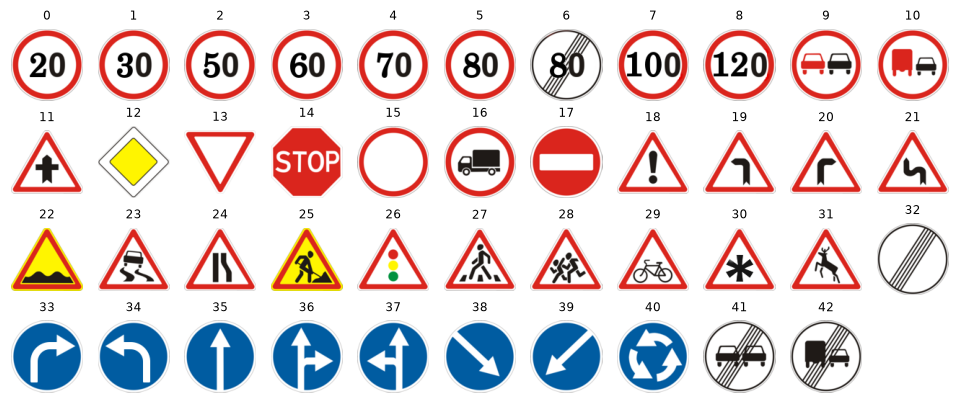

In [4]:
# Affichage des 43 pictogrammes de référence
fig, axes = plt.subplots(4, 11, figsize=(11, 4.4))
for ax in axes.flat:
    ax.axis("off")
for c, ax in zip(range(NUM_CLASSES), axes.flat):
    ax.imshow(Image.open(DATA_DIR / "Meta" / f"{c}.png"))
    ax.set_title(c, fontsize=8)
plt.show()

### 1.3 Nombre d'images par classe

In [5]:
# Tableau des effectifs par classe (train et test)
counts = pd.DataFrame({
    "panneau": CLASS_NAMES,
    "famille": [CLASS_FAMILY[c] for c in range(NUM_CLASSES)],
    "train": train_df["ClassId"].value_counts().sort_index(),
    "test": test_df["ClassId"].value_counts().sort_index(),
})
counts["% du train"] = (100 * counts["train"] / counts["train"].sum()).round(2)
counts

,panneau,famille,train,test,% du train
ClassId,,,,,
0,Limitation 20 km/h,Limitation de vitesse,210,60,0.54
1,Limitation 30 km/h,Limitation de vitesse,2220,720,5.66
2,Limitation 50 km/h,Limitation de vitesse,2250,750,5.74
3,Limitation 60 km/h,Limitation de vitesse,1410,450,3.60
4,Limitation 70 km/h,Limitation de vitesse,1980,660,5.05
5,Limitation 80 km/h,Limitation de vitesse,1860,630,4.74
6,Fin de limitation 80 km/h,Fin d'interdiction,420,150,1.07
7,Limitation 100 km/h,Limitation de vitesse,1440,450,3.67
8,Limitation 120 km/h,Limitation de vitesse,1410,450,3.60


In [6]:
# Effectifs par famille et classes extrêmes
by_family = counts.groupby("famille")[["train", "test"]].sum().sort_values("train", ascending=False)
by_family["% du train"] = (100 * by_family["train"] / by_family["train"].sum()).round(1)
print(by_family, "\n")

c_min, c_max = counts["train"].idxmin(), counts["train"].idxmax()
print(f"Classe la moins représentée : {c_min} ({CLASS_NAMES[c_min]}), {counts['train'].min()} images")
print(f"Classe la plus représentée : {c_max} ({CLASS_NAMES[c_max]}), {counts['train'].max()} images")
print(f"Rapport max / min : {counts['train'].max() / counts['train'].min():.1f}")

                       train  test  % du train
famille                                       
Limitation de vitesse  12780  4170        32.6
Danger                  7650  2370        19.5
Priorité                6360  2100        16.2
Interdiction            5640  1860        14.4
Obligation              5639  1770        14.4
Fin d'interdiction      1140   360         2.9 

Classe la moins représentée : 0 (Limitation 20 km/h), 210 images
Classe la plus représentée : 2 (Limitation 50 km/h), 2250 images
Rapport max / min : 10.7


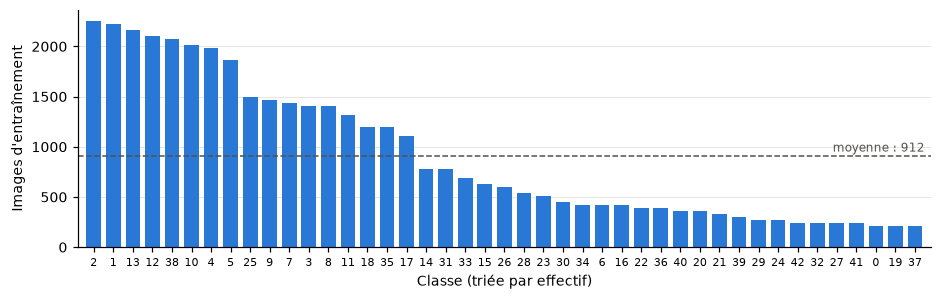

In [7]:
# Histogramme des effectifs par classe
order = counts["train"].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.bar(range(NUM_CLASSES), order.values, color=BLUE, width=0.75)
ax.axhline(order.mean(), color=GRAY, linestyle="--", linewidth=1)
ax.text(NUM_CLASSES - 0.5, order.mean() + 40, f"moyenne : {order.mean():.0f}", ha="right", fontsize=8, color=GRAY)
ax.set_xticks(range(NUM_CLASSES), order.index, fontsize=7)
ax.set_xlim(-0.8, NUM_CLASSES - 0.2)
ax.set_xlabel("Classe (triée par effectif)")
ax.set_ylabel("Images d'entraînement")
ax.grid(axis="x", visible=False)
plt.show()

Le déséquilibre est net : de 210 images (classes 0, 19 et 37) à 2 250 (classe 2), soit un facteur 10,7. Les limitations de vitesse font un tiers du train, et le test suit la même répartition. Une accuracy globale élevée pourrait cacher de mauvais résultats sur les petites classes : on regardera aussi la matrice de confusion, le rappel par classe et le F1 macro (moyenne non pondérée des F1 par classe).

### 1.4 Dimensions et format des images

In [8]:
# Tailles, format et séquences des images
for name, df in [("train", train_df), ("test", test_df)]:
    print(f"{name} : largeur {df['Width'].min()} à {df['Width'].max()} px (médiane {df['Width'].median():.0f}),"
          f" hauteur {df['Height'].min()} à {df['Height'].max()} px (médiane {df['Height'].median():.0f})")

ratio = train_df["Width"] / train_df["Height"]
print(f"Rapport largeur / hauteur : médiane {ratio.median():.2f}, 95 % des images entre {ratio.quantile(0.025):.2f} et {ratio.quantile(0.975):.2f}")
print(f"Images avec un côté < 32 px : {(train_df[['Width', 'Height']].min(axis=1) < 32).mean():.1%}")

# PIL ne lit que l'en-tête du fichier, c'est rapide même sur 50 000 images
paths = pd.concat([train_df["Path"], test_df["Path"]])
modes = pd.Series([Image.open(DATA_DIR / p).mode for p in paths]).value_counts()
print("Extensions :", paths.str.rsplit(".", n=1).str[-1].value_counts().to_dict(), "| modes PIL :", modes.to_dict())
print("Séquences dans le train :", train_df["track"].nunique(),
      "| images par séquence :", train_df["track"].value_counts().value_counts().to_dict())

train : largeur 25 à 243 px (médiane 43), hauteur 25 à 225 px (médiane 43)
test : largeur 25 à 266 px (médiane 43), hauteur 25 à 232 px (médiane 43)
Rapport largeur / hauteur : médiane 1.00, 95 % des images entre 0.87 et 1.15
Images avec un côté < 32 px : 16.6%


Extensions : {'png': 51839} | modes PIL : {'RGB': 51839}
Séquences dans le train : 1307 | images par séquence : {30: 1306, 29: 1}


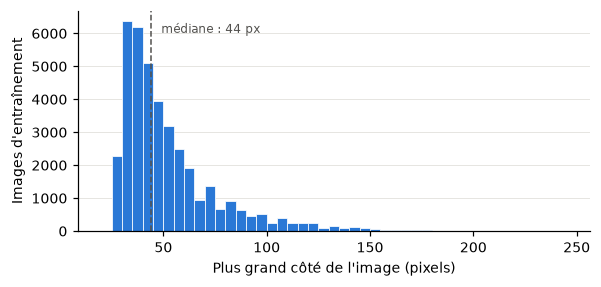

In [9]:
# Histogramme de la taille des images
side = train_df[["Width", "Height"]].max(axis=1)
fig, ax = plt.subplots(figsize=(6, 2.6))
ax.hist(side, bins=np.arange(20, 250, 5), color=BLUE, edgecolor="white", linewidth=0.5)
ax.axvline(side.median(), color=GRAY, linestyle="--", linewidth=1)
ax.text(side.median() + 5, ax.get_ylim()[1] * 0.9, f"médiane : {side.median():.0f} px", fontsize=8, color=GRAY)
ax.set_xlabel("Plus grand côté de l'image (pixels)")
ax.set_ylabel("Images d'entraînement")
ax.grid(axis="x", visible=False)
plt.show()

Toutes les images sont des PNG couleur RVB (8 bits par canal). Elles sont presque carrées mais de taille très variable (de 25×25 à plus de 200 px) et surtout petites : largeur et hauteur médianes de 43 px. Chaque panneau est entouré d'une marge d'environ 10 % (au moins 5 px).

Point clé pour la suite : le train est organisé en **séquences de 30 photos du même panneau**, prises pendant que la voiture s'en approche. Deux images d'une même séquence sont quasi identiques.

### 1.5 Exemples d'images

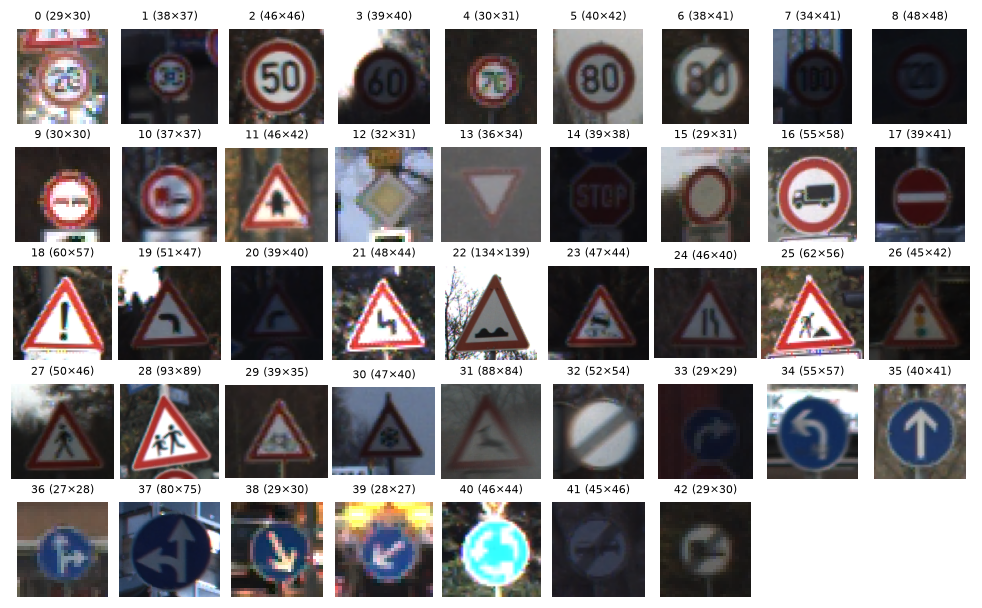

In [10]:
# Un exemple par classe
samples = train_df.groupby("ClassId").sample(1, random_state=SEED).sort_values("ClassId")
fig, axes = plt.subplots(5, 9, figsize=(9, 5.6))
for ax in axes.flat:
    ax.axis("off")
for ax, (_, row) in zip(axes.flat, samples.iterrows()):
    ax.imshow(Image.open(DATA_DIR / row["Path"]))
    ax.set_title(f"{row['ClassId']} ({row['Width']}×{row['Height']})", fontsize=7)
fig.tight_layout(h_pad=0.6, w_pad=0.3)
plt.show()

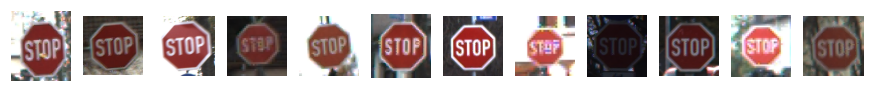

In [11]:
# Variabilité intra-classe : 12 Stop de séquences différentes
stops = train_df[train_df["ClassId"] == 14].groupby("track").sample(1, random_state=SEED).sample(12, random_state=SEED)
fig, axes = plt.subplots(1, 12, figsize=(10, 1.2))
for ax, (_, row) in zip(axes, stops.iterrows()):
    ax.imshow(Image.open(DATA_DIR / row["Path"]))
    ax.axis("off")
plt.show()

On est loin des pictogrammes : photos sombres, floues, surexposées ou minuscules, avec un éclairage, un angle et une netteté très variables au sein d'une même classe.

### 1.6 Préparation des données

- **Redimensionnement en 32×32** : le réseau attend une entrée de taille fixe. 32 px suffisent pour lire un panneau et gardent le modèle léger ; seules 17 % des images ont un côté inférieur à 32 px et doivent être agrandies. On ne recadre pas avec la zone d'intérêt fournie (colonnes `Roi.*`) : en conditions réelles, ce cadre exact n'est pas connu, autant apprendre avec la marge.
- **Normalisation** : division par 255 pour passer de [0, 255] à [0, 1], ce qui garde activations et gradients dans une plage raisonnable.
- **Labels** : on garde le numéro de classe (entier de 0 à 42) avec `sparse_categorical_crossentropy`. C'est équivalent au one-hot avec `categorical_crossentropy`, sans stocker la matrice.
- **Train / validation / test** : le train ajuste les poids. La validation mesure la généralisation, déclenche l'arrêt anticipé et sert à comparer les expériences puis à choisir le modèle final. Le test officiel (12 630 images) n'est utilisé qu'à l'évaluation finale.

**La validation est tirée par séquence, pas image par image** (20 % des séquences de chaque classe). Avec un tirage aléatoire, presque chaque image de validation aurait une quasi-copie dans le train et le score serait trop optimiste (vérifié par l'expérience E6).

`preprocess` est la seule porte d'entrée du modèle : la démonstration l'utilise aussi, pour que toute image soit traitée comme à l'entraînement.

In [12]:
# Prétraitement et chargement de toutes les images en mémoire
def preprocess(img):
    """Image RGB (PIL ou tableau uint8) -> tableau 32x32x3 float32 dans [0, 1].

    Seule porte d'entrée du modèle, aussi utilisée par la démonstration.
    """
    if not isinstance(img, Image.Image):
        img = Image.fromarray(img)
    img = img.convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.Resampling.BILINEAR)
    return np.asarray(img, dtype=np.float32) / 255.0


def load_split(df):
    def load(path):
        with Image.open(DATA_DIR / path) as img:
            return preprocess(img)

    with ThreadPoolExecutor() as pool:
        X = np.stack(list(pool.map(load, df["Path"])))
    return X, df["ClassId"].to_numpy()


t0 = time.time()
X_all, y_all = load_split(train_df)
X_test, y_test = load_split(test_df)
print(f"Chargement : {time.time() - t0:.0f} s | X_all {X_all.shape} {X_all.dtype}, min {X_all.min()}, max {X_all.max()}")

Chargement : 49 s | X_all (39209, 32, 32, 3) float32, min 0.0, max 1.0


In [13]:
# Validation par séquence : 20 % des séquences de chaque classe, sans quasi-copie dans le train
tracks = train_df[["track", "ClassId"]].drop_duplicates()
val_tracks = tracks.groupby("ClassId").sample(frac=0.2, random_state=SEED)["track"]
val_mask = train_df["track"].isin(val_tracks).to_numpy()

X_tr, y_tr = X_all[~val_mask], y_all[~val_mask]
X_val, y_val = X_all[val_mask], y_all[val_mask]
val_df = train_df[val_mask].reset_index(drop=True)

print(f"Train : {len(X_tr)} images | Validation : {len(X_val)} images ({val_mask.mean():.1%}) | Test : {len(X_test)} images")
print("Séquences communes entre train et validation :", len(set(train_df.loc[~val_mask, "track"]) & set(val_tracks)))
print("Classes présentes en validation :", len(np.unique(y_val)))

# Illustration : la perte sparse équivaut à ce one-hot (classe 14 = Stop), sans le stocker
print("One-hot de la classe 14 :", keras.utils.to_categorical([14], NUM_CLASSES).astype(int)[0])

Train : 31379 images | Validation : 7830 images (20.0%) | Test : 12630 images
Séquences communes entre train et validation : 0
Classes présentes en validation : 43
One-hot de la classe 14 : [0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0]


## Fonctions communes d'entraînement

Tous les modèles passent par `train` : même perte, même optimiseur (Adam), même arrêt anticipé (30 époques max, patience 5), donc comparaison à conditions égales. Seul le modèle final, une fois les choix faits, a un budget plus large (voir 6.2). Modèle et historique sont sauvegardés pour éviter de tout réentraîner.

In [14]:
# Fonctions communes : entraînement, courbes et scores de validation
EPOCHS = 30
BATCH_SIZE = 64


def train(name, build_fn, data=None, epochs=EPOCHS, batch_size=BATCH_SIZE, lr=1e-3, patience=5,
          class_weight=None, extra_callbacks=()):
    """Entraîne le modèle (ou le recharge s'il existe déjà) et renvoie (modèle, historique)."""
    model_path, hist_path = WORK_DIR / f"{name}.keras", WORK_DIR / f"{name}.json"
    if model_path.exists() and hist_path.exists() and not RETRAIN:
        history = json.loads(hist_path.read_text())
        print(f"{name} : déjà entraîné ({len(history['loss'])} époques, {history['time_s'] / 60:.0f} min), rechargé depuis {model_path}")
        return keras.models.load_model(model_path), history

    keras.utils.set_random_seed(SEED)  # même graine pour tous les modèles
    model = build_fn()
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    (x, y), (xv, yv) = data or ((X_tr, y_tr), (X_val, y_val))
    # restore_best_weights : on garde les poids de la meilleure perte de validation
    callbacks = [keras.callbacks.EarlyStopping(patience=patience, restore_best_weights=True), *extra_callbacks]

    start = time.time()
    fit = model.fit(x, y, validation_data=(xv, yv), epochs=epochs, batch_size=batch_size,
                    class_weight=class_weight, callbacks=callbacks, verbose=2)
    history = {k: [float(v) for v in values] for k, values in fit.history.items()}
    history["time_s"] = time.time() - start

    model.save(model_path)
    hist_path.write_text(json.dumps(history))
    return model, history


# Courbes de perte et d'accuracy
def plot_history(history, title):
    epochs = range(1, len(history["loss"]) + 1)
    best = int(np.argmin(history["val_loss"])) + 1
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3))
    for ax, key, label in [(ax1, "loss", "Perte"), (ax2, "accuracy", "Accuracy")]:
        ax.plot(epochs, history[key], color=BLUE, label="train")
        ax.plot(epochs, history[f"val_{key}"], color=ORANGE, label="validation")
        ax.axvline(best, color=GRAY, linestyle=":", linewidth=1)
        ax.set_xlabel("Époque")
        ax.set_ylabel(label)
        ax.legend()
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


# Scores de validation d'un modèle
def val_scores(model, history):
    proba = model.predict(X_val, batch_size=512, verbose=0)
    pred = proba.argmax(1)
    best = int(np.argmin(history["val_loss"]))
    return {
        "val_accuracy": (pred == y_val).mean(),
        "val_f1_macro": f1_score(y_val, pred, average="macro"),
        "val_loss": history["val_loss"][best],
        # Recalculée en inférence : dropout et augmentation faussent l'accuracy affichée à l'entraînement
        "train_accuracy": (model.predict(X_tr, batch_size=512, verbose=0).argmax(1) == y_tr).mean(),
        "meilleure époque": best + 1,
        "paramètres": model.count_params(),
        "temps (s)": round(history["time_s"]),
    }

## Partie 2 : modèle de référence (réseau dense)

Avant le CNN, un réseau entièrement connecté sert de point de comparaison :

`Image 32×32×3 → Flatten → Dense(256, ReLU) → Dense(43, Softmax)`

**Entrée.** `Flatten` aligne les 32 × 32 × 3 = 3 072 valeurs de l'image en un vecteur. Chaque pixel devient une entrée indépendante : le réseau perd la notion de voisinage, c'est la principale limite de ce modèle.

**Poids et biais.** Chaque neurone calcule une somme pondérée de ses entrées plus un biais : $z_j = \sum_i w_{ij} x_i + b_j$. Poids et biais sont les seuls paramètres appris : 3 072 × 256 + 256 = 786 688 pour la couche cachée.

**Propagation avant.** $a^{(l)} = f\big(W^{(l)} a^{(l-1)} + b^{(l)}\big)$ : de l'image aux activations cachées, puis aux 43 scores de sortie.

**Activation.** ReLU : $f(z) = \max(0, z)$. Sans non-linéarité, empiler des couches reviendrait à une seule transformation linéaire. ReLU est simple et son gradient vaut 1 pour $z > 0$, ce qui limite l'évanouissement du gradient (contrairement à la sigmoïde, qui sature).

**Sortie multiclasse.** 43 neurones suivis d'une softmax : $p_k = e^{z_k} / \sum_{j=1}^{43} e^{z_j}$. On obtient 43 probabilités de somme 1 ; la classe prédite est la plus probable. (Avec 2 classes, un neurone sigmoïde suffirait.)

**Perte.** Entropie croisée : $L = -\log p_y$, avec $p_y$ la probabilité de la vraie classe. Elle vaut 0 si le réseau est sûr de la bonne réponse et explose s'il lui donne une probabilité proche de 0.

**Rétropropagation.** Les dérivées $\partial L / \partial w$ sont calculées de la sortie vers l'entrée par la règle de dérivation en chaîne. Avec softmax + entropie croisée, le gradient sur les scores est simple : $\partial L / \partial z_k = p_k - \mathbb{1}[k = y]$.

**Descente de gradient.** $w \leftarrow w - \eta \, \partial L / \partial w$, avec $\eta$ le learning rate, estimé sur des mini-batchs de 64 images. Nous utilisons Adam, qui adapte le pas de chaque paramètre à partir de moyennes mobiles de ses gradients et de leurs carrés.

In [15]:
# Réseau dense de référence
def build_dense():
    return keras.Sequential([
        keras.Input((IMG_SIZE, IMG_SIZE, 3)),
        layers.Flatten(),
        layers.Dense(256, activation="relu"),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ], name="dense_baseline")


build_dense().summary()

Model: "dense_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       786,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │        11,051 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 797,739 (3.04 MB)

 Trainable params: 797,739 (3.04 MB)

 Non-trainable params: 0 (0.00 B)

dense_baseline : déjà entraîné (14 époques, 2 min), rechargé depuis /home/guinat/.cache/signavision/dense_baseline.keras


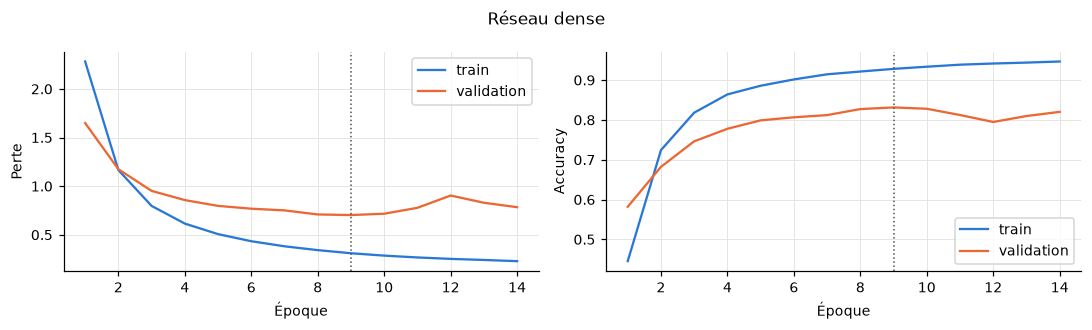

,val_accuracy,val_f1_macro,val_loss,train_accuracy,meilleure époque,paramètres,temps (s)
Réseau dense (référence),0.831418,0.766547,0.703315,0.913445,9.0,797739.0,113.0


In [16]:
# Entraînement du réseau dense et premiers résultats
dense_model, dense_hist = train("dense_baseline", build_dense)
plot_history(dense_hist, "Réseau dense")
results = {"Réseau dense (référence)": val_scores(dense_model, dense_hist)}
pd.DataFrame(results).T

Le réseau dense atteint 83,1 % en validation (F1 macro 0,77), loin des 2,3 % du hasard, mais il plafonne vite. La perte de validation est minimale à l'époque 9 puis remonte, alors que celle d'entraînement continue de baisser ; l'écart entre train (91,3 %) et validation (83,1 %) montre qu'il retient en partie le train au lieu de généraliser. C'est attendu : près de 800 000 paramètres et des pixels traités indépendamment, donc décaler le panneau de deux pixels change toute l'entrée. Le CNN doit corriger cela.

## Partie 3 : construction d'un CNN avec Keras

### 3.1 Les briques d'un CNN

- **Filtre et convolution.** Petite matrice de poids (ici 3×3) qu'on fait glisser sur l'image : à chaque position, on multiplie par le morceau d'image et on somme. Sur une image couleur, le filtre fait 3×3×3 (27 poids + 1 biais). Il apprend à réagir à un motif local (bord, coin, chiffre) où qu'il soit : les poids sont partagés sur toutes les positions.
- **Feature maps.** Chaque filtre produit une carte 2D indiquant où son motif apparaît. 32 filtres donnent 32 cartes empilées en canaux, que la couche suivante combine en motifs plus complexes.
- **Kernel 3×3 partout.** Deux convolutions 3×3 voient une zone 5×5 avec moins de poids qu'un filtre 5×5 (18 contre 25 par canal) et une non-linéarité en plus.
- **Stride 1.** C'est le pooling qui réduit la taille.
- **Padding `same`.** Une bordure de zéros conserve la taille (sans padding, une convolution 3×3 retire un pixel par côté). Taille de sortie = ⌊(n + 2p − k) / s⌋ + 1, ici (32 + 2 − 3) / 1 + 1 = 32.
- **ReLU** après chaque convolution, comme dans le réseau dense.
- **MaxPooling 2×2.** Garde le maximum de chaque bloc : hauteur et largeur divisées par 2, calcul des couches suivantes divisé par 4, et une petite translation du panneau change peu la sortie.
- **Flatten, Dense, softmax.** Le `Flatten` met les feature maps à plat, une couche dense combine les caractéristiques, puis `Dense(43, softmax)` donne les probabilités.

### 3.2 Notre architecture

Point de départ volontairement simple, dans l'esprit du schéma du sujet : deux blocs « convolution + ReLU + max pooling » à 32 puis 64 filtres, puis une couche dense de 256 neurones. On double les filtres quand la résolution est divisée par deux, pour compenser la perte spatiale par plus de motifs. La partie 6 la fera évoluer ; `build_cnn` est paramétrée pour que chaque expérience ne change qu'un argument.

In [17]:
# Augmentation, constructeur du CNN et tableau des couches
# Couches d'augmentation (actives seulement à l'entraînement)
def make_augmentation():
    # Pas de retournement horizontal : « tourner à gauche » deviendrait « tourner à droite »
    return keras.Sequential([
        layers.RandomRotation(10 / 360),
        layers.RandomZoom(0.15),
        layers.RandomTranslation(0.1, 0.1),
        layers.RandomBrightness(0.25, value_range=(0, 1)),
        layers.RandomContrast(0.3, value_range=(0, 1)),
    ], name="augmentation")


# CNN paramétrable
def build_cnn(filters=(32, 64), convs_per_block=1, dense=256, dropout=0.0, batchnorm=False, augment=False):
    """CNN paramétré : chaque expérience de la partie 6 ne change qu'un argument."""
    model = keras.Sequential(name="cnn")
    model.add(keras.Input((IMG_SIZE, IMG_SIZE, 3)))
    if augment:
        model.add(make_augmentation())
    for f in filters:
        for _ in range(convs_per_block):
            if batchnorm:  # conv sans biais -> BN -> ReLU (β de la BN remplace le biais)
                model.add(layers.Conv2D(f, 3, padding="same", use_bias=False))
                model.add(layers.BatchNormalization())
                model.add(layers.Activation("relu"))
            else:
                model.add(layers.Conv2D(f, 3, padding="same", activation="relu"))
        model.add(layers.MaxPooling2D(2))
        if dropout:
            model.add(layers.Dropout(dropout / 2))  # moitié moins fort que celui avant la sortie
    model.add(layers.Flatten())
    model.add(layers.Dense(dense, activation="relu"))
    if dropout:
        model.add(layers.Dropout(dropout))
    model.add(layers.Dense(NUM_CLASSES, activation="softmax"))
    return model


# Forme de sortie et paramètres de chaque couche
def layer_table(model):
    rows = [{"couche": type(l).__name__, "sortie": "×".join(map(str, l.output.shape[1:])), "paramètres": l.count_params()}
            for l in model.layers]
    table = pd.DataFrame([{"couche": "Input", "sortie": "×".join(map(str, model.input_shape[1:])), "paramètres": 0}] + rows)
    table.loc[len(table)] = ["Total", "", table["paramètres"].sum()]
    return table


layer_table(build_cnn())

,couche,sortie,paramètres
0,Input,32×32×3,0
1,Conv2D,32×32×32,896
2,MaxPooling2D,16×16×32,0
3,Conv2D,16×16×64,18496
4,MaxPooling2D,8×8×64,0
5,Flatten,4096,0
6,Dense,256,1048832
7,Dense,43,11051
8,Total,,1079275


### 3.3 Évolution des dimensions et nombre de paramètres

- **Conv2D(32)** : 32×32×3 → 32×32×32 (le padding `same` conserve la taille). Paramètres : (3 × 3 × 3 + 1) × 32 = 896.
- **MaxPooling** : → 16×16×32, aucun paramètre.
- **Conv2D(64)** : → 16×16×64. Chaque filtre couvre les 32 feature maps : (3 × 3 × 32 + 1) × 64 = 18 496.
- **MaxPooling** : → 8×8×64.
- **Flatten** : 8 × 8 × 64 = 4 096 valeurs.
- **Dense(256)** : 4 096 × 256 + 256 = 1 048 832.
- **Dense(43)** : 256 × 43 + 43 = 11 051.

Les convolutions pèsent moins de 20 000 paramètres grâce au partage des poids. La couche dense après le `Flatten` en concentre 97 % : c'est elle qui risque de surapprendre. Ajouter un bloc convolutif réduit le `Flatten` et donc ce nombre (E1).

## Partie 4 : entraînement du réseau

Choix communs à tous les modèles (sauf le budget d'époques du modèle final, voir 6.2) :

- **Perte** : `sparse_categorical_crossentropy` (labels entiers). C'est la perte naturelle avec une softmax : maximum de vraisemblance et gradient simple, $p - y$.
- **Optimiseur** : Adam, learning rate $10^{-3}$ (valeur standard). Il converge vite sans réglage fin.
- **Batch size 64** : 491 mises à jour par époque sur 31 379 images. Plus petit, le gradient est plus bruité et l'époque plus lente ; beaucoup plus grand, il demande plus de mémoire et généralise souvent un peu moins bien.
- **Époques** : 30 au maximum avec `EarlyStopping` : arrêt quand la perte de validation ne s'améliore plus pendant 5 époques, en reprenant les poids de la meilleure. Pas besoin de fixer le nombre d'époques à l'avance.
- **Métriques** : accuracy pendant l'entraînement ; ensuite F1 macro, matrice de confusion et rappel par classe, à cause du déséquilibre.

cnn_v1 : déjà entraîné (11 époques, 6 min), rechargé depuis /home/guinat/.cache/signavision/cnn_v1.keras


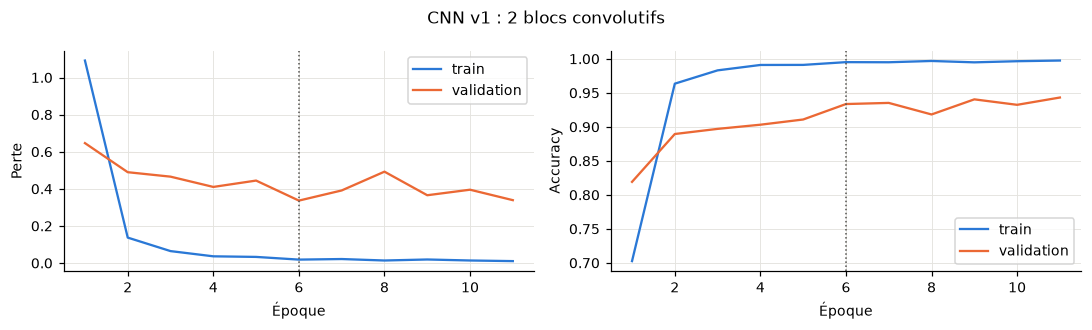

,val_accuracy,val_f1_macro,val_loss,train_accuracy,meilleure époque,paramètres,temps (s)
Réseau dense (référence),0.831418,0.766547,0.703315,0.913445,9.0,797739.0,113.0
CNN v1,0.933589,0.879008,0.336816,0.996941,6.0,1079275.0,338.0


In [18]:
# Entraînement du CNN v1
cnn_v1, cnn_v1_hist = train("cnn_v1", build_cnn)
plot_history(cnn_v1_hist, "CNN v1 : 2 blocs convolutifs")
results["CNN v1"] = val_scores(cnn_v1, cnn_v1_hist)
pd.DataFrame(results).T

### Interprétation des courbes

Le CNN v1 atteint 93,4 % en validation (F1 macro 0,88), dix points de plus que le réseau dense pour un nombre de paramètres du même ordre (1,08 M contre 0,80 M). Le gain vient de la structure : les filtres partagés repèrent un motif où qu'il soit.

Le surapprentissage est net : l'accuracy d'entraînement dépasse 96 % dès la deuxième époque et la perte tombe presque à zéro (0,01). La perte de validation est minimale à l'époque 6 (0,34) puis oscille entre 0,34 et 0,49. Le modèle connaît le train par cœur (99,7 %), et les six points d'écart avec la validation mesurent ce qu'il ne généralise pas. L'arrêt anticipé a gardé l'époque 6 (ligne pointillée).

Après l'époque 6, l'accuracy de validation monte encore un peu alors que la perte stagne : le modèle se trompe moins souvent, mais avec beaucoup d'assurance quand il se trompe, ce que l'entropie croisée pénalise lourdement. La régularisation (dropout, batch normalization, augmentation) est testée en partie 6.

### Ce que voit le réseau

Feature maps de la première convolution pour un Stop : chaque filtre réagit à quelque chose de différent (bords, zones rouges, lettres claires).

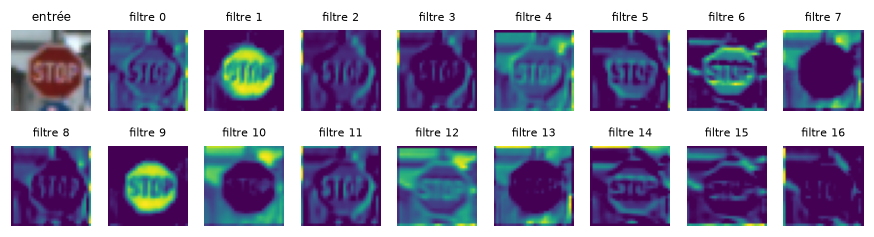

In [19]:
# Feature maps de la première convolution sur un Stop
stop_idx = np.where(y_val == 14)[0][5]
first_conv = keras.Model(cnn_v1.inputs, cnn_v1.layers[0].output)
maps = first_conv.predict(X_val[stop_idx : stop_idx + 1], verbose=0)[0]

fig, axes = plt.subplots(2, 9, figsize=(10, 2.5))
axes[0, 0].imshow(X_val[stop_idx])
axes[0, 0].set_title("entrée", fontsize=8)
for i, ax in enumerate(axes.flat[1:]):
    ax.imshow(maps[:, :, i], cmap="viridis")
    ax.set_title(f"filtre {i}", fontsize=7)
for ax in axes.flat:
    ax.axis("off")
plt.show()

## Partie 5 : évaluation et analyse des erreurs

On analyse le CNN v1 sur la **validation**. Le test reste de côté jusqu'à la fin de la partie 6 : l'analyse des erreurs oriente nos expériences et ne doit pas s'appuyer sur lui. Les mêmes fonctions serviront à l'évaluation finale.

Avec des classes déséquilibrées, l'accuracy peut rester excellente alors qu'une petite classe est mal reconnue. On regarde donc chaque classe :

- **rappel** : part des images d'une classe retrouvées par le modèle (sur 100 vrais Stop, combien sont prédits Stop) ;
- **précision** : part des prédictions d'une classe qui sont justes (sur 100 prédits Stop, combien en sont vraiment) ;
- **F1** : moyenne harmonique des deux. Le **F1 macro** est la moyenne des 43 F1 : chaque classe compte autant, quelle que soit sa taille.

In [20]:
# Fonctions d'évaluation : métriques, graphiques et tableaux d'erreurs
# Accuracy et F1 macro d'un modèle
def evaluate(model, X, y):
    proba = model.predict(X, batch_size=512, verbose=0)
    pred = proba.argmax(1)
    print(f"Accuracy : {(pred == y).mean():.2%} | F1 macro : {f1_score(y, pred, average='macro'):.4f} | erreurs : {(pred != y).sum()} / {len(y)}")
    return proba, pred


# Matrice de confusion (échelle log)
def plot_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
    fig, ax = plt.subplots(figsize=(7.5, 6.5))
    im = ax.imshow(np.ma.masked_equal(cm, 0), cmap="Blues", norm=LogNorm(vmin=1, vmax=cm.max()))
    ax.set_xticks(range(NUM_CLASSES), range(NUM_CLASSES), fontsize=6)
    ax.set_yticks(range(NUM_CLASSES), range(NUM_CLASSES), fontsize=6)
    ax.set_xlabel("Classe prédite")
    ax.set_ylabel("Vraie classe")
    ax.grid(False)
    fig.colorbar(im, ax=ax, shrink=0.8, label="Nombre d'images (échelle log, cases vides = 0)")
    ax.set_title(title)
    plt.show()


# Erreurs de classe à classe les plus fréquentes
def top_confusions(y_true, y_pred, n=10):
    cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
    np.fill_diagonal(cm, 0)
    rows = []
    for t, p in zip(*np.unravel_index(np.argsort(cm, axis=None)[::-1][:n], cm.shape)):
        if cm[t, p]:
            rows.append({"vraie classe": f"{t} · {CLASS_NAMES[t]}", "prédite": f"{p} · {CLASS_NAMES[p]}",
                         "erreurs": cm[t, p], "% de la classe": round(100 * cm[t, p] / (y_true == t).sum(), 1)})
    return pd.DataFrame(rows)


# Précision, rappel et F1 par classe
def per_class_table(y_true, y_pred):
    report = classification_report(y_true, y_pred, labels=list(range(NUM_CLASSES)), output_dict=True, zero_division=0)
    table = pd.DataFrame([report[str(c)] for c in range(NUM_CLASSES)]).round(3)
    table.insert(0, "panneau", CLASS_NAMES)
    table.insert(1, "famille", [CLASS_FAMILY[c] for c in range(NUM_CLASSES)])
    return table.rename(columns={"precision": "précision", "recall": "rappel", "f1-score": "f1", "support": "images"})


# Accuracy par famille
def family_table(y_true, y_pred):
    fam = pd.Series(y_true).map(CLASS_FAMILY)
    return (pd.DataFrame({"famille": fam, "correct": y_true == y_pred})
            .groupby("famille")["correct"].agg(images="size", accuracy="mean")
            .sort_values("accuracy").round(4))


# Rappel par classe, trié
def plot_recall(table, title):
    t = table.sort_values("rappel")
    fig, ax = plt.subplots(figsize=(10, 2.6))
    ax.bar(range(NUM_CLASSES), t["rappel"], color=BLUE, width=0.75)
    ax.set_xticks(range(NUM_CLASSES), t.index, fontsize=7)
    ax.set_ylim(max(0, t["rappel"].min() - 0.05), 1.005)
    ax.set_xlabel("Classe (triée par rappel)")
    ax.set_ylabel("Rappel")
    ax.grid(axis="x", visible=False)
    ax.set_title(title)
    plt.show()


def sharpness(gray):
    """Variance du laplacien de chaque image : faible pour une image floue."""
    lap = 4 * gray[:, 1:-1, 1:-1] - gray[:, :-2, 1:-1] - gray[:, 2:, 1:-1] - gray[:, 1:-1, :-2] - gray[:, 1:-1, 2:]
    return lap.var(axis=(1, 2))


# Taille, luminosité, netteté et erreur de chaque image
def condition_table(meta, X, y, pred):
    gray = X.mean(axis=3)
    return pd.DataFrame({
        "taille (px)": meta[["Width", "Height"]].min(axis=1).to_numpy(),
        "luminosité": gray.mean(axis=(1, 2)),
        "netteté": sharpness(gray),
        "erreur": pred != y,
    })


# Taux d'erreur par quartile de chaque indicateur
def plot_conditions(cond, title):
    fmt = {"taille (px)": "{:.0f}", "luminosité": "{:.2f}", "netteté": "{:.3f}"}
    fig, axes = plt.subplots(1, 3, figsize=(10, 2.8), sharey=True)
    for ax, col in zip(axes, fmt):
        rate = 100 * cond.groupby(pd.qcut(cond[col], 4, duplicates="drop"), observed=True)["erreur"].mean()
        ax.bar(range(len(rate)), rate.values, color=BLUE, width=0.7)
        ax.set_xticks(range(len(rate)), [f"{fmt[col].format(iv.left)}–{fmt[col].format(iv.right)}" for iv in rate.index], fontsize=7)
        ax.set_xlabel(f"{col}, par quartile")
        ax.grid(axis="x", visible=False)
    axes[0].set_ylabel("Taux d'erreur (%)")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


# Grille d'images avec vraie classe, prédiction et probabilité
def show_predictions(X, y, proba, idx, title, ncols=8):
    rows = int(np.ceil(len(idx) / ncols))
    fig, axes = plt.subplots(rows, ncols, figsize=(ncols * 1.5, rows * 2.05), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, i in zip(axes.flat, idx):
        p = proba[i].argmax()
        ok = p == y[i]
        ax.imshow(X[i])
        ax.set_title(f"{'✓' if ok else '✗'} vraie : {short_name(y[i], 14)}\nprédite : {short_name(p, 14)}\nproba : {proba[i, p]:.0%}",
                     fontsize=6.5, color=GOOD if ok else BAD)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

Accuracy : 93.36% | F1 macro : 0.8790 | erreurs : 520 / 7830


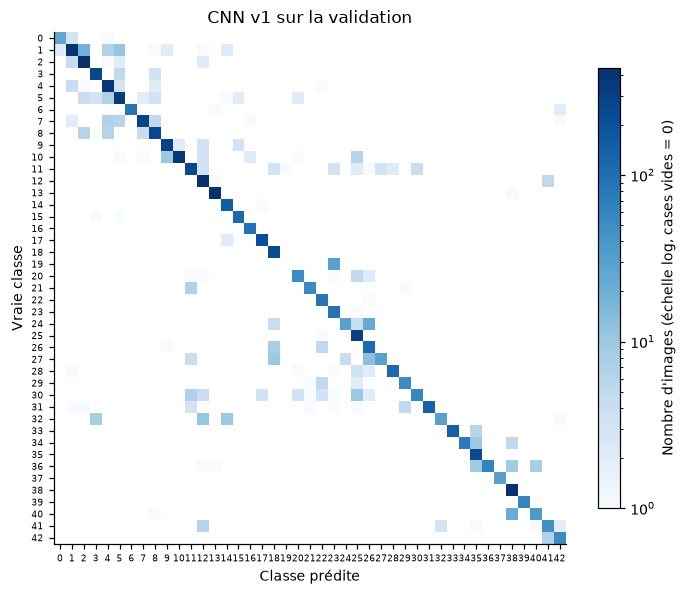

In [21]:
# Évaluation de v1 sur la validation
v1_proba, v1_pred = evaluate(cnn_v1, X_val, y_val)
plot_confusion(y_val, v1_pred, "CNN v1 sur la validation")

In [22]:
# Principales confusions de v1
top_confusions(y_val, v1_pred)

,vraie classe,prédite,erreurs,% de la classe
0,19 · Virage à gauche,23 · Chaussée glissante,30,100.0
1,24 · Chaussée rétrécie par la droite,26 · Feux tricolores,23,38.3
2,40 · Carrefour giratoire,38 · Contournement par la droite,22,36.7
3,1 · Limitation 30 km/h,2 · Limitation 50 km/h,19,4.2
4,27 · Passage piétons,26 · Feux tricolores,13,21.7
5,1 · Limitation 30 km/h,5 · Limitation 80 km/h,11,2.4
6,32 · Fin de toutes les interdictions,12 · Route prioritaire,11,18.3
7,32 · Fin de toutes les interdictions,14 · Stop,10,16.7
8,"10 · Interdiction de dépasser (> 3,5 t)",9 · Interdiction de dépasser,10,2.6
9,30 · Neige ou verglas,25 · Travaux,10,11.1


Corrélation de Spearman entre le rappel et le nombre d'images d'entraînement : 0.50


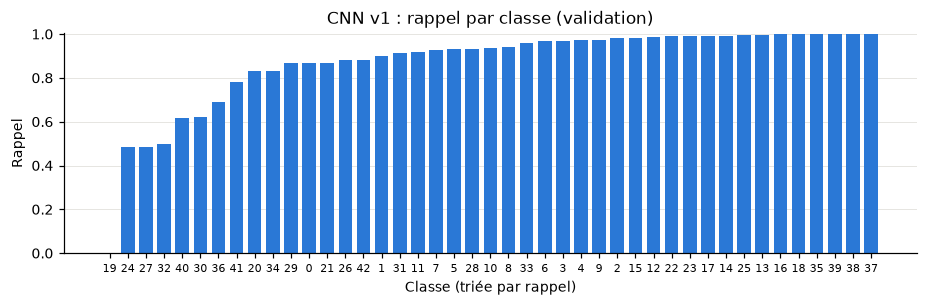

                       images  accuracy
famille                                
Fin d'interdiction        270    0.8037
Danger                   1530    0.8758
Obligation               1140    0.9368
Limitation de vitesse    2520    0.9448
Interdiction             1110    0.9676
Priorité                 1260    0.9762 



,panneau,famille,précision,rappel,f1,images,images train
19,Virage à gauche,Danger,0.000,0.000,0.000,30.0,180
24,Chaussée rétrécie par la droite,Danger,0.879,0.483,0.624,60.0,210
27,Passage piétons,Danger,0.906,0.483,0.630,60.0,180
32,Fin de toutes les interdictions,Fin d'interdiction,0.909,0.500,0.645,60.0,180
40,Carrefour giratoire,Obligation,0.804,0.617,0.698,60.0,300
30,Neige ou verglas,Danger,0.933,0.622,0.747,90.0,360
36,Tout droit ou à droite,Obligation,1.000,0.689,0.816,90.0,300
41,Fin d'interdiction de dépasser,Fin d'interdiction,0.797,0.783,0.790,60.0,180


In [23]:
# Rappel par classe et par famille pour v1
v1_classes = per_class_table(y_val, v1_pred)
v1_classes["images train"] = np.bincount(y_tr, minlength=NUM_CLASSES)
print(f"Corrélation de Spearman entre le rappel et le nombre d'images d'entraînement : "
      f"{v1_classes['rappel'].corr(v1_classes['images train'], method='spearman'):.2f}")
plot_recall(v1_classes, "CNN v1 : rappel par classe (validation)")
print(family_table(y_val, v1_pred), "\n")
v1_classes.sort_values("rappel").head(8)

Sur la validation, le CNN v1 fait 520 erreurs sur 7 830 images. Les familles les mieux reconnues sont la priorité (97,6 %), dont trois panneaux sur quatre ont une forme unique, et les interdictions (96,8 %). Les plus difficiles sont les fins d'interdiction (80,4 %) et les dangers (87,6 %).

Les confusions les plus fréquentes ont presque toutes la même cause : deux panneaux de même forme et de même couleur, qui ne diffèrent que par un petit pictogramme central, à peine lisible en 32×32.

- Les 30 images de « virage à gauche » sont toutes prédites « chaussée glissante » (deux triangles rouges à courbe noire).
- « Chaussée rétrécie par la droite » et « passage piétons » partent vers « feux tricolores », un autre triangle de danger.
- « Carrefour giratoire » est pris pour « contournement par la droite » (deux disques bleus à flèches blanches).
- Les limitations de vitesse se confondent entre elles (30 lu 50 ou 80) : seul le chiffre change.

Les classes difficiles sont aussi les moins représentées : corrélation de Spearman de 0,50 entre rappel et nombre d'images d'entraînement, et les huit classes au rappel le plus faible ont 180 à 360 images pour une moyenne de 730. Mais la validation est petite : « virage à gauche » n'y a qu'une séquence de 30 images, et une séquence ratée suffit à faire tomber son rappel à 0.

### Erreurs et conditions de prise de vue

On calcule trois indicateurs par image, on les découpe en quartiles et on compare le taux d'erreur d'un groupe à l'autre :

- **taille** : plus petit côté de l'image d'origine. Un panneau lointain occupe peu de pixels et ses détails sont à peine lisibles ;
- **luminosité** : moyenne des pixels en niveaux de gris du 32×32, de 0 (noir) à 1 (blanc) ;
- **netteté** : variance du laplacien du 32×32 en niveaux de gris, faible pour une image floue.

La netteté est mesurée après redimensionnement : les petites images agrandies paraissent floues, donc netteté et taille sont liées. L'angle de vue ne se mesure pas sans annotation ; on le juge à l'œil sur les exemples d'erreurs, comme la ressemblance entre classes (tableau des confusions).

Corrélation de Spearman taille / netteté : 0.36


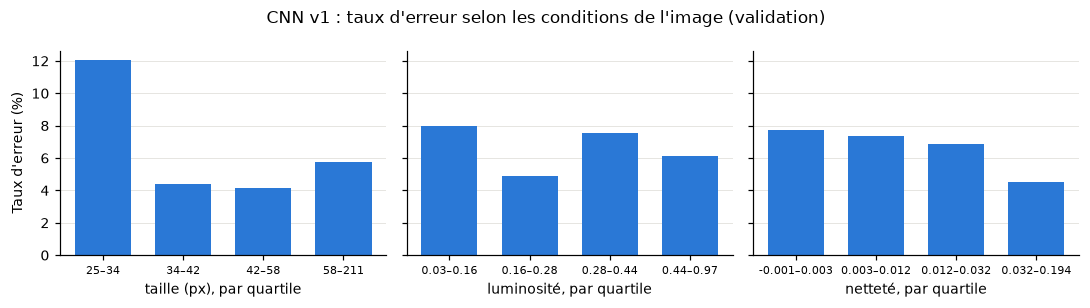

In [24]:
# Taux d'erreur de v1 selon taille, luminosité et netteté
v1_cond = condition_table(val_df, X_val, y_val, v1_pred)
print("Corrélation de Spearman taille / netteté :", round(v1_cond["taille (px)"].corr(v1_cond["netteté"], method="spearman"), 2))
plot_conditions(v1_cond, "CNN v1 : taux d'erreur selon les conditions de l'image (validation)")

La taille est le facteur le plus net : les images dont le plus petit côté fait 34 px ou moins ont environ 12 % d'erreurs, contre 4 à 6 % pour les trois autres quartiles. Le flou joue aussi (près de 8 % pour les plus floues, moins de 5 % pour les plus nettes), mais en partie via la taille (corrélation de Spearman de 0,36). L'effet de la luminosité est moins régulier : les plus sombres sont un peu plus souvent mal classées (8 %), mais le troisième quartile n'est pas loin.

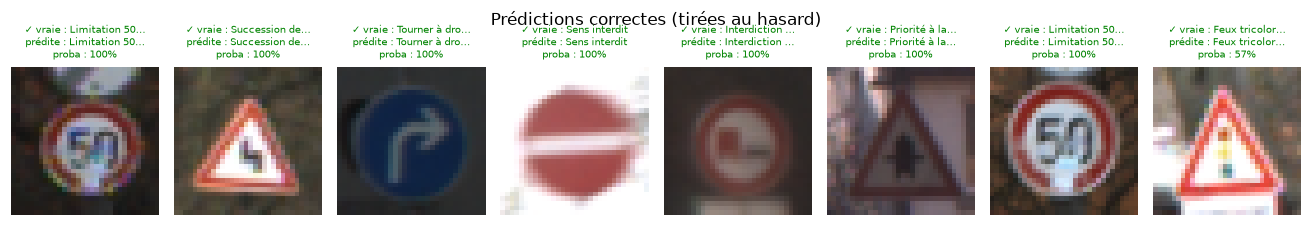

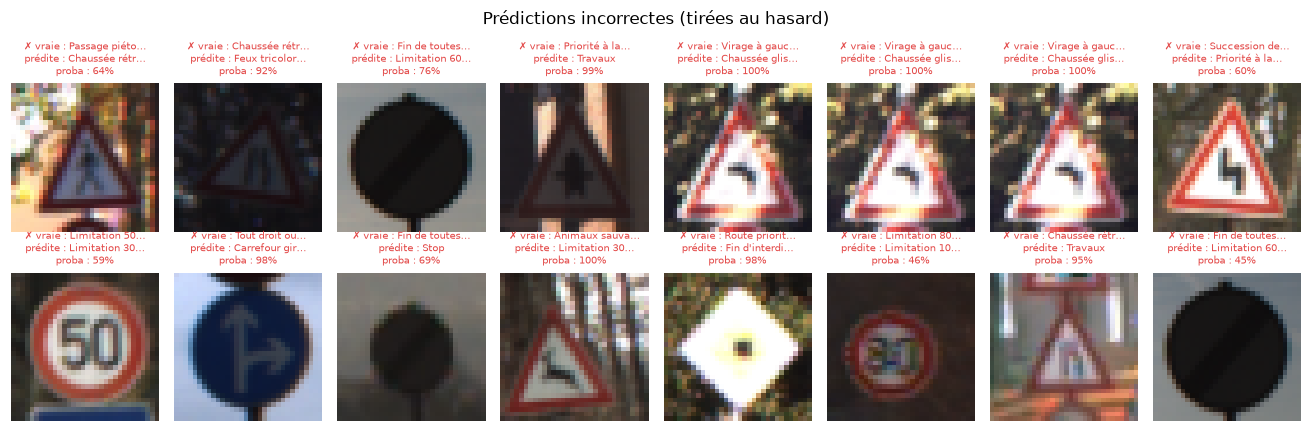

In [25]:
# Exemples de prédictions correctes et incorrectes
rng = np.random.default_rng(SEED)
correct = np.where(v1_pred == y_val)[0]
wrong = np.where(v1_pred != y_val)[0]
show_predictions(X_val, y_val, v1_proba, rng.choice(correct, 8, replace=False), "Prédictions correctes (tirées au hasard)")
show_predictions(X_val, y_val, v1_proba, rng.choice(wrong, min(16, len(wrong)), replace=False), "Prédictions incorrectes (tirées au hasard)")

Les erreurs tirées au hasard confirment les tableaux. Plusieurs images sont presque noires : « fin de toutes les interdictions » (disque blanc barré) devient un disque sombre sans détail, pris pour une limitation ou un Stop. Les trois « virage à gauche » de la sélection viennent de la même séquence et sont prédits « chaussée glissante » à 100 % : le modèle se trompe avec une confiance totale, ce que l'entropie croisée pénalise très lourdement (partie 4). Les autres erreurs touchent des panneaux petits ou flous (un 80 illisible pris pour un 100), surexposés, vus de biais ou accompagnés d'un second panneau (un 50 net avec un panonceau dessous, lu 30). La plupart restent compréhensibles à cette résolution, pas toutes : un « animaux sauvages » incliné, pourtant bien triangulaire, est lu 30 km/h à 100 %.

## Partie 6 : expérimentation et amélioration

### 6.1 Expériences

Chaque expérience part du CNN v1 et ne change qu'une chose, pour attribuer l'effet observé à cette modification. Tout est comparé sur la validation.

Précaution : chaque configuration n'est entraînée qu'une fois, et la validation ne compte que 261 séquences très corrélées. D'une époque à l'autre, l'accuracy de validation du v1 varie déjà de plus de 2 points. On ne retient donc un effet que s'il est net (plusieurs points) et cohérent entre accuracy, F1 macro et perte de validation.

| Expérience | Modification | Ce qu'on teste |
|---|---|---|
| E1 | 3e bloc convolutif (128 filtres) | Plus de profondeur, et un `Flatten` 2 fois plus petit (moins de paramètres denses) |
| E2 | 2 convolutions par bloc | Plus de capacité d'extraction à résolution égale |
| E3 | Dropout (0,25 après chaque pooling, 0,5 avant la sortie) | Régularisation contre le surapprentissage de la partie 4 |
| E4 | Batch normalization après chaque convolution | Stabilité et vitesse de l'entraînement |
| E5 | Data augmentation | Robustesse à l'angle, au cadrage et à l'éclairage |
| E6 | Validation tirée image par image | Mesurer à quel point ce découpage surestime l'accuracy |

- **Data augmentation** : seulement des transformations qui ne changent pas le sens du panneau (rotation ±10°, zoom ±15 %, décalage ±10 %, luminosité, contraste). Pas de retournement : un « tourner à gauche » retourné garderait son ancien label. Ces couches ne sont actives qu'à l'entraînement.
- **Dropout** : à l'entraînement, chaque activation est mise à zéro avec une probabilité p, et les autres sont multipliées par 1/(1 − p) pour garder la même moyenne. Le réseau ne peut plus compter sur quelques neurones spécialisés, ce qui limite la mémorisation. En prédiction, tous les neurones sont utilisés.
- **Batch normalization** : placée entre chaque convolution et sa ReLU, elle ramène chaque canal à une moyenne nulle et une variance de 1 sur le mini-batch, puis applique une échelle γ et un décalage β appris. L'échelle des activations reste stable d'une couche à l'autre. En prédiction, on utilise des moyennes et variances glissantes. β jouant le rôle de biais, ces convolutions n'en ont pas (`use_bias=False`).

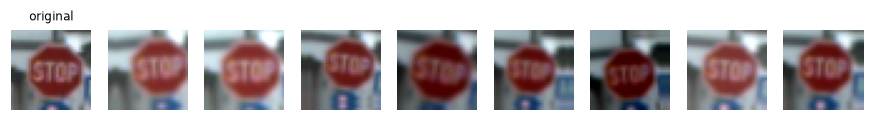

In [26]:
# Aperçu de l'augmentation sur un Stop
aug_demo = make_augmentation()
demo = np.repeat(X_val[stop_idx : stop_idx + 1], 8, axis=0)
fig, axes = plt.subplots(1, 9, figsize=(10, 1.4))
for ax, img in zip(axes, [X_val[stop_idx], *np.clip(aug_demo(demo, training=True).numpy(), 0, 1)]):
    ax.imshow(img)
    ax.axis("off")
axes[0].set_title("original", fontsize=8)
plt.show()

In [27]:
# Entraînement des expériences E1 à E5
# Chaque expérience ne modifie qu'un argument de build_cnn par rapport à v1
EXPERIMENTS = {
    "E1 · 3 blocs": dict(filters=(32, 64, 128)),
    "E2 · 2 conv. par bloc": dict(convs_per_block=2),
    "E3 · Dropout": dict(dropout=0.5),
    "E4 · Batch normalization": dict(batchnorm=True),
    "E5 · Data augmentation": dict(augment=True),
}
histories = {"CNN v1": cnn_v1_hist}
for i, (label, kwargs) in enumerate(EXPERIMENTS.items(), start=1):
    model, hist = train(f"cnn_e{i}", lambda kw=kwargs: build_cnn(**kw))
    histories[label] = hist
    results[label] = val_scores(model, hist)

cnn_e1 : déjà entraîné (11 époques, 7 min), rechargé depuis /home/guinat/.cache/signavision/cnn_e1.keras


cnn_e2 : déjà entraîné (14 époques, 15 min), rechargé depuis /home/guinat/.cache/signavision/cnn_e2.keras


cnn_e3 : déjà entraîné (18 époques, 8 min), rechargé depuis /home/guinat/.cache/signavision/cnn_e3.keras


cnn_e4 : déjà entraîné (12 époques, 9 min), rechargé depuis /home/guinat/.cache/signavision/cnn_e4.keras


cnn_e5 : déjà entraîné (26 époques, 11 min), rechargé depuis /home/guinat/.cache/signavision/cnn_e5.keras


In [28]:
# E6 : même CNN v1, mais validation tirée image par image
rand_mask = np.random.default_rng(SEED).random(len(y_all)) < val_mask.mean()
random_split = ((X_all[~rand_mask], y_all[~rand_mask]), (X_all[rand_mask], y_all[rand_mask]))
cnn_rand, cnn_rand_hist = train("cnn_e6_random_split", build_cnn, data=random_split)
rand_val_acc = cnn_rand_hist["val_accuracy"][int(np.argmin(cnn_rand_hist["val_loss"]))]
print(f"E6 : accuracy de validation affichée {rand_val_acc:.2%}"
      f" (contre {results['CNN v1']['val_accuracy']:.2%} pour le même modèle validé par séquence)")

cnn_e6_random_split : déjà entraîné (27 époques, 11 min), rechargé depuis /home/guinat/.cache/signavision/cnn_e6_random_split.keras


E6 : accuracy de validation affichée 99.53% (contre 93.36% pour le même modèle validé par séquence)


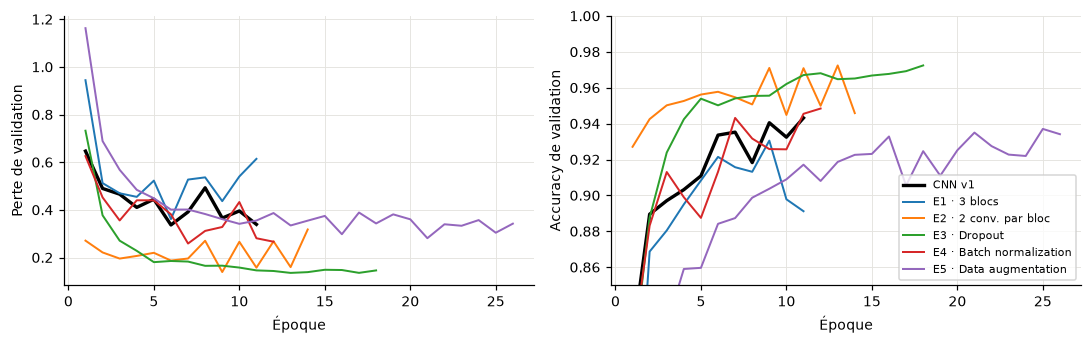

,val_accuracy,val_f1_macro,val_loss,train_accuracy,meilleure époque,paramètres,temps (s)
Réseau dense (référence),83.14%,0.7665,0.7033,91.34%,9,"797,739",113
CNN v1,93.36%,0.8790,0.3368,99.69%,6,"1,079,275",338
E1 · 3 blocs,92.15%,0.8570,0.3615,99.57%,6,"628,843",447
E2 · 2 conv. par bloc,97.10%,0.9561,0.1392,99.96%,9,"1,125,451",897
E3 · Dropout,96.48%,0.9317,0.1356,99.92%,13,"1,079,275",488
E4 · Batch normalization,94.32%,0.9012,0.2589,99.93%,7,"1,079,563",538
E5 · Data augmentation,93.50%,0.8934,0.2812,99.76%,21,"1,079,275",682


In [29]:
# Courbes de validation et tableau comparatif des expériences
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.2), sharex=True)
for label, hist in histories.items():
    style = dict(color="black", linewidth=2.2) if label == "CNN v1" else dict(linewidth=1.3)
    ax1.plot(range(1, len(hist["val_loss"]) + 1), hist["val_loss"], label=label, **style)
    ax2.plot(range(1, len(hist["val_accuracy"]) + 1), hist["val_accuracy"], label=label, **style)
ax1.set_ylabel("Perte de validation")
ax2.set_ylabel("Accuracy de validation")
ax2.set_ylim(0.85, 1.0)
for ax in (ax1, ax2):
    ax.set_xlabel("Époque")
ax2.legend(fontsize=7, loc="lower right")
fig.tight_layout()
plt.show()

table = pd.DataFrame(results).T
table.style.format({"val_accuracy": "{:.2%}", "val_f1_macro": "{:.4f}", "val_loss": "{:.4f}", "train_accuracy": "{:.2%}",
                    "paramètres": "{:,.0f}", "meilleure époque": "{:.0f}", "temps (s)": "{:.0f}"}).background_gradient(subset=["val_accuracy"], cmap="Blues")

**Tableau comparatif des expériences** (résultats sur la validation) :

| | Modification | Accuracy val. | F1 macro | Observation |
|---|---|---|---|---|
| v1 | référence | 93,4 % | 0,879 | surapprentissage net (écart train/val de 6,3 points) |
| E1 | 3e bloc (128 filtres) | 92,1 % | 0,857 | dans le bruit, 42 % de paramètres en moins |
| E2 | 2 convolutions par bloc | 97,1 % | 0,956 | meilleur gain |
| E3 | dropout | 96,5 % | 0,932 | perte de validation la plus basse (0,136) |
| E4 | batch normalization | 94,3 % | 0,901 | dans le bruit, perte plus basse que v1 |
| E5 | data augmentation | 93,5 % | 0,893 | apprend lentement, sans doute arrêté trop tôt |
| E6 | validation image par image | 99,5 % | – | score gonflé par les quasi-copies |

L'accuracy d'entraînement du tableau chiffré est recalculée en mode inférence (sans dropout ni augmentation) pour que les écarts soient comparables.

- **E2, deux convolutions par bloc** : le gain le plus net, 97,1 % (+3,7 points) et un F1 macro de 0,88 à 0,96. Deux convolutions 3×3 avant chaque pooling analysent une zone 5×5 à pleine résolution, ce qui aide sans doute à distinguer des panneaux de même forme qui ne diffèrent que par leur pictogramme.
- **E3, dropout** : 96,5 % (+3,1 points) et la plus faible perte de validation (0,136), qui baisse régulièrement sans les oscillations des autres modèles. L'écart train/validation passe de 6,3 à 3,4 points, uniquement parce que la validation monte : l'accuracy d'entraînement ne baisse pas (99,9 %).
- **E4, batch normalization** : 94,3 %, un point de mieux que v1, dans la marge de bruit. Pas de convergence plus rapide (meilleure époque 7 contre 6), mais une perte de validation plus basse (0,26 contre 0,34).
- **E1, troisième bloc** : 92,1 %, un point de moins que v1, dans le bruit. En revanche 42 % de paramètres en moins (629 000 contre 1,08 million) : le `Flatten` passe de 4 096 à 2 048 valeurs.
- **E5, data augmentation** : 93,5 %, comme v1, mais avec une perte plus basse (0,28 contre 0,34), donc des erreurs moins catégoriques. Le modèle apprend lentement (meilleure époque 21) et l'arrêt anticipé l'a coupé à l'époque 26, trop tôt pour en profiter.
- **E6, validation image par image** : 99,5 % contre 93,4 % pour la même architecture validée par séquence. Ces six points sont en grande partie une illusion : presque chaque image de validation a une quasi-copie dans le train. Le test le confirmera en 6.3.

### 6.2 Modèle final

E2 et E3 semblent corriger deux défauts différents (distinction des pictogrammes, mémorisation) : on garde les deux. On ajoute :

- la **batch normalization**, qui stabilise l'entraînement d'un réseau plus profond ;
- la **data augmentation**, dont l'essai E5 a été arrêté trop tôt, mais qui devrait aider avec un entraînement plus long ;
- le **troisième bloc** : seul, il ne fait pas mieux que v1 (dans le bruit), mais il divise par deux la couche dense, qui concentre presque tous les paramètres. Il ne réduit pas le surapprentissage (7,4 points d'écart train/validation contre 6,3 pour v1) : c'est au dropout de s'en charger.

Ces effets ne s'additionnent pas forcément : seule la validation du modèle combiné peut confirmer ce choix.

**Budget d'entraînement du modèle final.** Les expériences gardent le même budget (30 époques, patience 5) pour rester comparables. Le modèle final a 60 époques au maximum, une patience de 10, et un learning rate divisé par deux quand la perte de validation stagne 4 époques (`ReduceLROnPlateau`, minimum $10^{-5}$). Avec l'augmentation et le dropout, le réseau apprend plus lentement et un arrêt après 5 époques sans progrès risquerait de couper trop tôt. La baisse du learning rate affine les poids en fin d'entraînement. Les deux mécanismes surveillent la perte de **validation** : le test n'intervient toujours pas.

cnn_final : déjà entraîné (29 époques, 69 min), rechargé depuis /home/guinat/.cache/signavision/cnn_final.keras


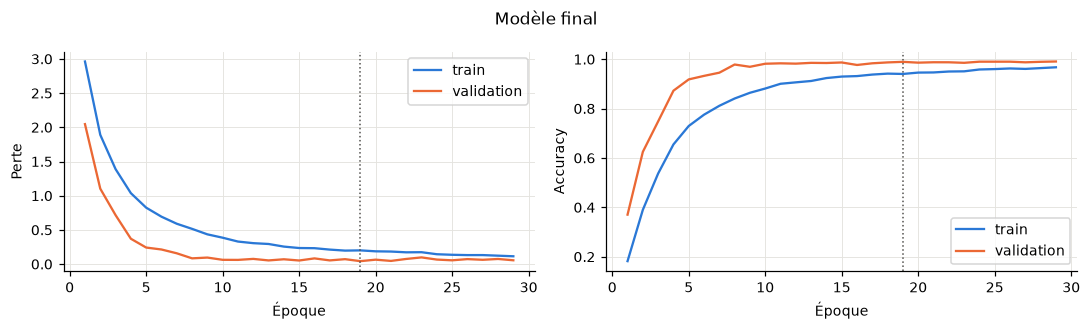

,couche,sortie,paramètres
0,Input,32×32×3,0
1,Sequential,32×32×3,0
2,Conv2D,32×32×32,864
3,BatchNormalization,32×32×32,128
4,Activation,32×32×32,0
5,Conv2D,32×32×32,9216
6,BatchNormalization,32×32×32,128
7,Activation,32×32×32,0
8,MaxPooling2D,16×16×32,0
9,Dropout,16×16×32,0


In [30]:
# Combinaison des choix retenus en 6.2, avec un budget d'entraînement élargi
FINAL_CONFIG = dict(filters=(32, 64, 128), convs_per_block=2, dropout=0.5, batchnorm=True, augment=True)

final_model, final_hist = train(
    "cnn_final", lambda: build_cnn(**FINAL_CONFIG), epochs=60, patience=10,
    extra_callbacks=[keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=4, min_lr=1e-5)],
)
plot_history(final_hist, "Modèle final")
results["Modèle final"] = val_scores(final_model, final_hist)
layer_table(final_model)

**Architecture finale, couche par couche** (tableau ci-dessus) :

- **Augmentation** (`Sequential`) : 32×32×3 inchangé, aucun paramètre, active seulement à l'entraînement.
- **Bloc 1** : 2 × Conv2D(32) → 32×32×32, puis MaxPooling → 16×16×32. Sans biais : 3×3×3×32 = 864 et 3×3×32×32 = 9 216 paramètres.
- **Bloc 2** : 2 × Conv2D(64) → 16×16×64, puis MaxPooling → 8×8×64 ; 18 432 + 36 864 paramètres.
- **Bloc 3** : 2 × Conv2D(128) → 8×8×128, puis MaxPooling → 4×4×128 ; 73 728 + 147 456 paramètres.
- **BatchNormalization** : 4 paramètres par canal (γ, β appris ; moyenne et variance glissantes non entraînables), soit 1 792 dont 896 non entraînables. **Dropout** : aucun paramètre.
- **Flatten** : 4 × 4 × 128 = 2 048 valeurs, contre 4 096 pour v1.
- **Dense(256)** : 2 048 × 256 + 256 = 524 544 ; **Dense(43)** : 256 × 43 + 43 = 11 051.

Total : 823 947 paramètres, environ 24 % de moins que v1 (1 079 275), avec six convolutions au lieu de deux. Dense(256) reste la plus lourde (64 %), mais le troisième bloc a divisé sa taille par deux.

Les courbes du modèle final n'ont plus rien à voir avec celles de v1. L'accuracy d'entraînement affichée reste sous celle de validation (94 % contre 99 % à la meilleure époque) : elle est mesurée sur des images augmentées avec le dropout actif, donc sur une tâche plus difficile. Plus de surapprentissage visible : la perte de validation descend à 0,043 à l'époque 19 (contre 0,34 pour v1) puis se stabilise. Le learning rate a été réduit deux fois (époques 24 et 28) sans améliorer ce minimum, et l'arrêt anticipé a coupé à l'époque 29. Avec 98,95 % en validation, le modèle combiné fait mieux que chaque expérience seule (97,1 % pour E2) : le choix de 6.2 est confirmé. Il est aussi plus léger que v1 (824 000 paramètres contre 1,08 million), mais bien plus long à entraîner : 69 minutes sur CPU.

### 6.3 Évaluation finale sur le jeu de test

Les choix sont faits : on ouvre enfin le test. Les modèles sont évalués une seule fois sur les 12 630 images, sans rien modifier ensuite.

In [31]:
# Première et seule utilisation du test
test_rows = {}
for label, model, val_acc in [("Réseau dense (référence)", dense_model, results["Réseau dense (référence)"]["val_accuracy"]),
                              ("CNN v1", cnn_v1, results["CNN v1"]["val_accuracy"]),
                              ("E6 · CNN v1, validation aléatoire", cnn_rand, rand_val_acc),
                              ("Modèle final", final_model, results["Modèle final"]["val_accuracy"])]:
    pred = model.predict(X_test, batch_size=512, verbose=0).argmax(1)
    test_rows[label] = {"accuracy validation": val_acc, "accuracy test": (pred == y_test).mean(),
                        "F1 macro test": f1_score(y_test, pred, average="macro"), "erreurs test": int((pred != y_test).sum())}
pd.DataFrame(test_rows).T.style.format({"accuracy validation": "{:.2%}", "accuracy test": "{:.2%}", "F1 macro test": "{:.4f}", "erreurs test": "{:.0f}"})

,accuracy validation,accuracy test,F1 macro test,erreurs test
Réseau dense (référence),83.14%,80.22%,0.7478,2498
CNN v1,93.36%,92.00%,0.8806,1011
"E6 · CNN v1, validation aléatoire",99.53%,94.98%,0.9260,634
Modèle final,98.95%,98.35%,0.9642,209


Sur le test, le modèle final atteint **98,35 %** (F1 macro 0,964), soit 209 erreurs sur 12 630 images, contre 80,2 % pour le réseau dense et 92,0 % pour le CNN v1.

Le tableau valide aussi notre méthode. La validation par séquence était fiable : elle annonçait 93,4 % pour v1 et 98,95 % pour le modèle final, le test donne 92,0 % et 98,35 %. La validation aléatoire d'E6 annonçait 99,5 % pour un modèle qui ne fait que 95,0 % sur le test. Ce modèle est un peu meilleur que v1, sans doute parce qu'il a vu des images de toutes les séquences et s'est entraîné plus longtemps (27 époques contre 11), mais on est loin des 99,5 % affichés : avec ce découpage, on aurait cru le problème résolu dès le premier CNN.

Accuracy : 98.35% | F1 macro : 0.9642 | erreurs : 209 / 12630


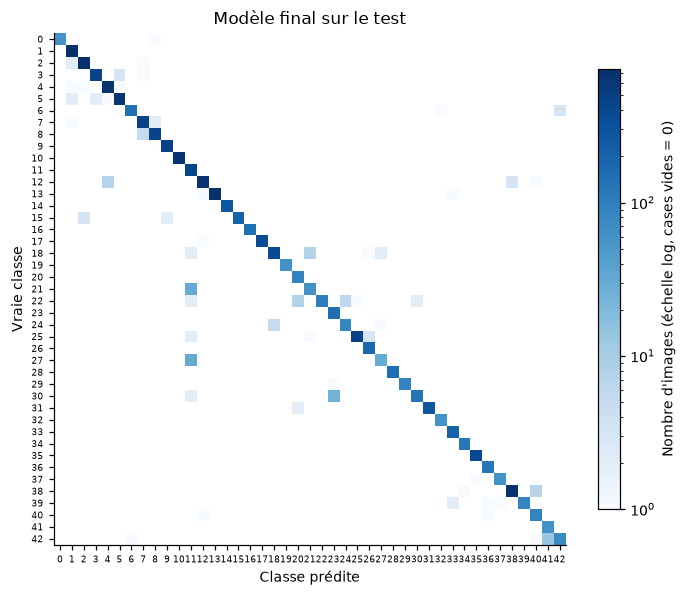

,vraie classe,prédite,erreurs,% de la classe
0,21 · Succession de virages,11 · Priorité à la prochaine intersection,30,33.3
1,27 · Passage piétons,11 · Priorité à la prochaine intersection,29,48.3
2,30 · Neige ou verglas,23 · Chaussée glissante,24,16.0
3,"42 · Fin d'interdiction de dépasser (> 3,5 t)",41 · Fin d'interdiction de dépasser,13,14.4
4,18 · Autres dangers,21 · Succession de virages,8,2.1
5,22 · Chaussée déformée,20 · Virage à droite,8,6.7
6,38 · Contournement par la droite,40 · Carrefour giratoire,7,1.0
7,12 · Route prioritaire,4 · Limitation 70 km/h,7,1.0
8,22 · Chaussée déformée,24 · Chaussée rétrécie par la droite,6,5.0
9,8 · Limitation 120 km/h,7 · Limitation 100 km/h,5,1.1


In [32]:
# Évaluation du modèle final sur le test
final_proba, final_pred = evaluate(final_model, X_test, y_test)
plot_confusion(y_test, final_pred, "Modèle final sur le test")
top_confusions(y_test, final_pred)

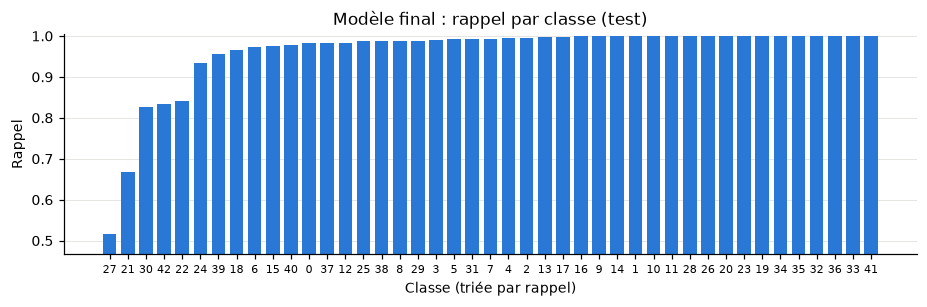

                       images  accuracy
famille                                
Danger                   2370    0.9443
Fin d'interdiction        360    0.9472
Obligation               1770    0.9915
Priorité                 2100    0.9938
Limitation de vitesse    4170    0.9942
Interdiction             1860    0.9968 



,panneau,famille,précision,rappel,f1,images
27,Passage piétons,Danger,0.912,0.517,0.660,60.0
21,Succession de virages,Danger,0.870,0.667,0.755,90.0
30,Neige ou verglas,Danger,0.984,0.827,0.899,150.0
42,"Fin d'interdiction de dépasser (> 3,5 t)",Fin d'interdiction,0.962,0.833,0.893,90.0
22,Chaussée déformée,Danger,1.000,0.842,0.914,120.0
24,Chaussée rétrécie par la droite,Danger,0.933,0.933,0.933,90.0
39,Contournement par la gauche,Obligation,1.000,0.956,0.977,90.0
18,Autres dangers,Danger,0.987,0.967,0.977,390.0


In [33]:
# Rappel par classe et par famille sur le test
final_classes = per_class_table(y_test, final_pred)
plot_recall(final_classes, "Modèle final : rappel par classe (test)")
print(family_table(y_test, final_pred), "\n")
final_classes.sort_values("rappel").head(8)

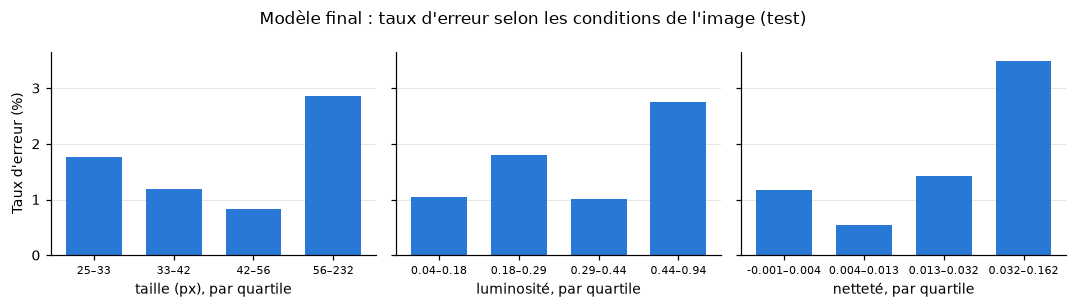

In [34]:
# Taux d'erreur du modèle final selon les conditions de l'image
final_cond = condition_table(test_df, X_test, y_test, final_pred)
plot_conditions(final_cond, "Modèle final : taux d'erreur selon les conditions de l'image (test)")

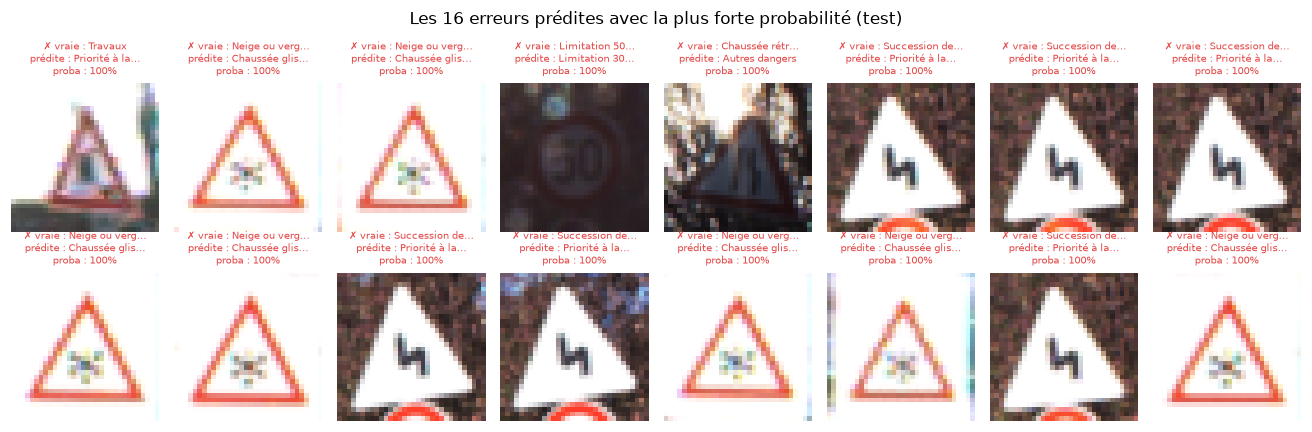

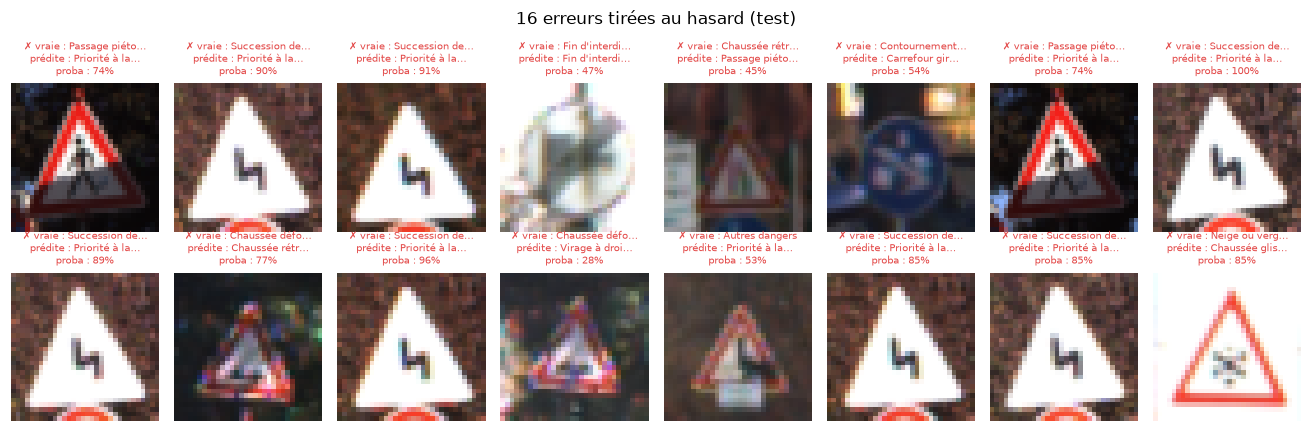

In [35]:
# Erreurs les plus confiantes et erreurs tirées au hasard
wrong = np.where(final_pred != y_test)[0]
confident_wrong = wrong[np.argsort(-final_proba[wrong].max(1))]
show_predictions(X_test, y_test, final_proba, confident_wrong[:16], "Les 16 erreurs prédites avec la plus forte probabilité (test)")
show_predictions(X_test, y_test, final_proba, np.random.default_rng(SEED).choice(wrong, 16, replace=False), "16 erreurs tirées au hasard (test)")

Les 209 erreurs restantes sont très concentrées : 17 classes sur 43 ont un rappel de 100 % et 32 un rappel d'au moins 98 %. Quatre familles dépassent 99 % (interdictions 99,7 %, limitations 99,4 %, priorité 99,4 %, obligations 99,2 %), alors que les dangers tombent à 94,4 % et les fins d'interdiction à 94,7 %. Quatre confusions font à elles seules 96 erreurs, presque la moitié :

- « succession de virages » prise 30 fois pour « priorité à la prochaine intersection » ;
- « passage piétons » prise 29 fois pour la même classe ;
- « neige ou verglas » prise 24 fois pour « chaussée glissante » ;
- « fin d'interdiction de dépasser (> 3,5 t) » prise 13 fois pour sa variante sans camion.

Ces erreurs arrivent par paquets, car les images de test viennent aussi de séquences d'un même panneau. Les « succession de virages » mal classées viennent presque toutes de la même scène (un grand triangle net devant un fond sombre, avec le haut d'un autre panneau rouge en bas). Les « neige ou verglas » sont surexposées et le flocon devient une tache colorée. Le modèle se trompe sur presque toute la séquence, souvent avec une probabilité très élevée (jusqu'à 100 %).

Cela explique le graphique des conditions, inverse de celui de v1 : ce sont maintenant les images les plus grandes, claires et nettes qui ont le taux d'erreur le plus élevé. Les erreurs restantes viennent de quelques séquences atypiques, nettes mais trompeuses. Tous les taux restent sous 3,5 %.

## Démonstration du modèle final

`predict_sign` prend une image de panneau déjà recadrée (chemin, image PIL ou tableau), applique le même `preprocess` qu'à l'entraînement et affiche les trois classes les plus probables. Pendant la soutenance : `predict_sign("mon_panneau.jpg")` sur une photo recadrée autour du panneau. Le modèle ne cherche pas un panneau dans une scène complète : la détection est hors du périmètre du projet.

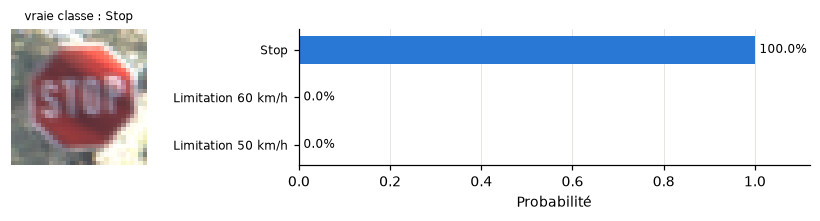

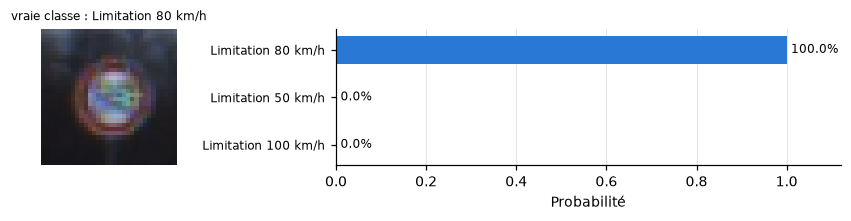

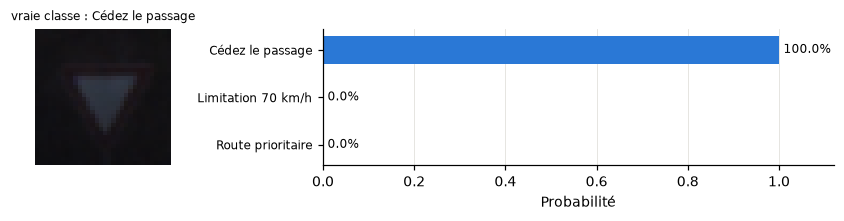

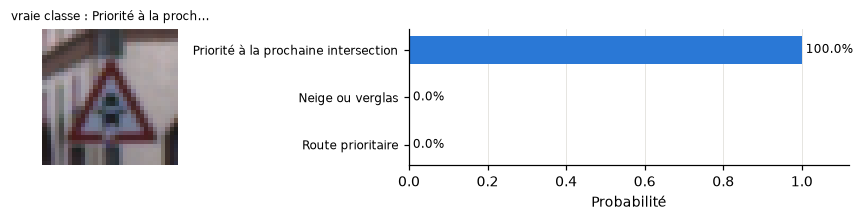

In [36]:
# Démonstration : prédiction sur une image
def on_gray(img):
    """Pose une image à fond transparent sur un gris moyen."""
    background = Image.new("RGBA", img.size, (128, 128, 128, 255))
    return Image.alpha_composite(background, img.convert("RGBA")).convert("RGB")


def predict_sign(img, top=3, title=None):
    """Affiche l'image telle que le réseau la voit et les `top` classes les plus probables."""
    if isinstance(img, (str, Path)):
        # Les photos de téléphone stockent leur rotation dans l'EXIF, que PIL n'applique pas seul
        img = ImageOps.exif_transpose(Image.open(img))
    if isinstance(img, Image.Image) and (img.mode in ("RGBA", "LA", "PA") or "transparency" in img.info):
        img = on_gray(img)
    x = preprocess(img)
    proba = final_model.predict(x[None], verbose=0)[0]
    best = np.argsort(proba)[::-1][:top]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7.5, 1.9), gridspec_kw={"width_ratios": [1, 3]}, layout="constrained")
    ax1.imshow(x)
    ax1.axis("off")
    if title:
        ax1.set_title(title, fontsize=8)
    ax2.barh(range(top), proba[best][::-1], color=BLUE, height=0.6)
    ax2.set_yticks(range(top), [CLASS_NAMES[c] for c in best][::-1], fontsize=8)
    ax2.set_xlim(0, 1.12)
    ax2.set_xlabel("Probabilité")
    for k, c in enumerate(best[::-1]):
        ax2.text(proba[c] + 0.01, k, f"{proba[c]:.1%}", va="center", fontsize=8)
    ax2.grid(axis="y", visible=False)
    plt.show()
    return int(best[0]), float(proba[best[0]])


# Quatre images du test
for _, row in test_df.sample(4, random_state=7).iterrows():
    predict_sign(DATA_DIR / row["Path"], title=f"vraie classe : {short_name(row['ClassId'], 20)}")

Test plus éloigné de l'entraînement : les 43 pictogrammes officiels de `Meta/`, des dessins nets sur fond transparent, posés sur un fond gris.

Pictogrammes reconnus : 26 / 43


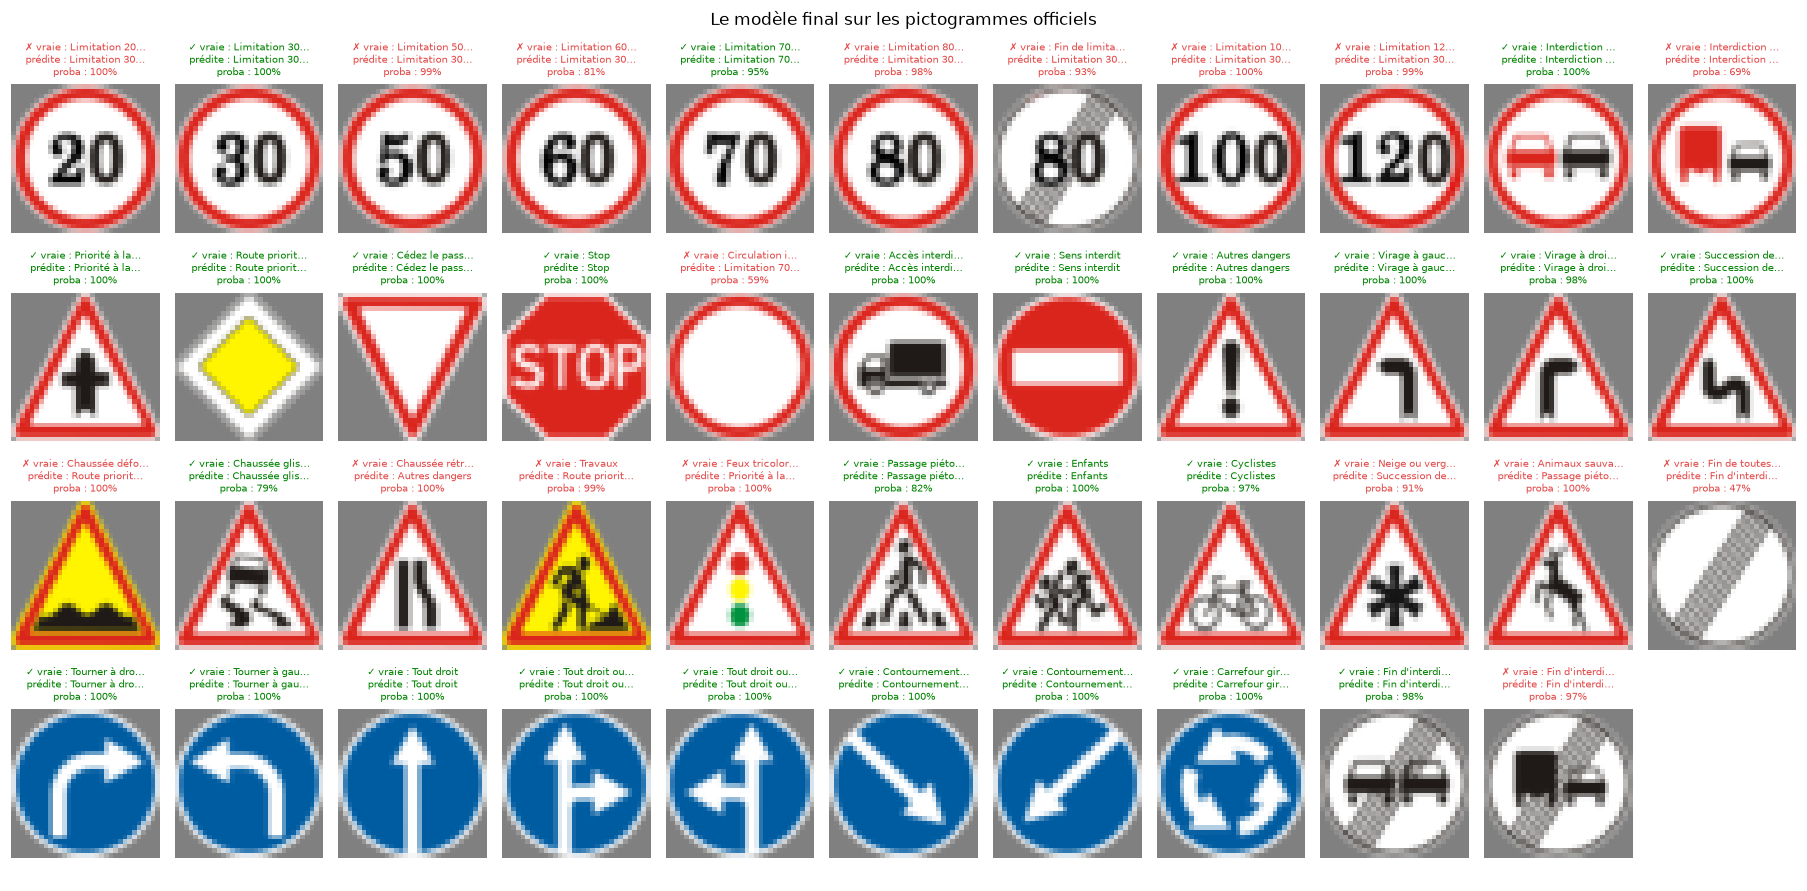

In [37]:
# Test hors distribution : pictogrammes officiels sur fond gris
pictos = np.stack([preprocess(on_gray(Image.open(DATA_DIR / "Meta" / f"{c}.png"))) for c in range(NUM_CLASSES)])
picto_proba = final_model.predict(pictos, verbose=0)
picto_pred = picto_proba.argmax(1)
print(f"Pictogrammes reconnus : {(picto_pred == np.arange(NUM_CLASSES)).sum()} / {NUM_CLASSES}")
show_predictions(pictos, np.arange(NUM_CLASSES), picto_proba, range(NUM_CLASSES), "Le modèle final sur les pictogrammes officiels", ncols=11)

26 pictogrammes sur 43 sont reconnus, et le détail montre ce que le modèle a vraiment appris. Formes et couleurs passent bien : toutes les obligations (disques bleus) et les quatre panneaux de priorité sont reconnus. En revanche, toutes les limitations de vitesse sauf le 70 sont lues « 30 km/h », souvent à 99 ou 100 % : sur ces dessins aux chiffres plus gros et plus épais que sur les photos, le modèle ne lit pas vraiment le nombre. Les deux triangles à fond jaune (« chaussée déformée » et « travaux », en version de chantier) sont ratés : le modèle ne les a jamais vus de cette couleur. Il a donc appris les photos de GTSRB plutôt que le panneau idéal.

## Conclusion

Le modèle final reconnaît 98,35 % des 12 630 images de test (F1 macro 0,964), contre 80,2 % pour le réseau dense et 92,0 % pour notre premier CNN. Le gain vient d'abord de l'architecture (les convolutions exploitent la structure de l'image, et deux convolutions par bloc aident à lire des pictogrammes de quelques pixels), puis de la régularisation (dropout, batch normalization, augmentation), qui fait disparaître le surapprentissage.

Ce que nous retenons surtout : l'importance de la façon de valider. Les images de GTSRB arrivent par séquences de 30 photos quasi identiques, et une validation image par image annonçait 99,5 % pour un modèle qui fait 95,0 % sur le test. En validant par séquence, l'écart avec le test reste sous 1,5 point pour v1 et le modèle final (2,9 points pour le réseau dense).

Limites : chaque configuration n'a été entraînée qu'une fois, donc les écarts de un ou deux points entre expériences ne sont pas significatifs ; en 32×32, certains pictogrammes sont illisibles et les erreurs restantes se concentrent sur quelques séquences de panneaux de danger ; le test sur les pictogrammes montre que le modèle a appris les photos de GTSRB plus que le panneau lui-même ; enfin il classe un panneau déjà recadré et ne sait pas le trouver dans une scène.

Pour aller plus loin : plusieurs graines par configuration, une résolution plus élevée (48×48 ou 64×64), puis les extensions du sujet non traitées (transfer learning, détection avec YOLO, traitement vidéo).